# Generate a Mock Dataset

Generate a simulated TF dataset as follows:

* Merge the loa photometric + spectroscopic catalogs with the SGA2020 catalog.
* Apply all photometric corrections used in the TF analysis.
* Cross-match with one of the BGS mocks.
* Apply photometric and morphological cuts used in the PV survey for late-type galaxies.
* Generate mock rotational velocities using an inverted TFR best fit from the data.
* Generate mock TFR distances. 

In [131]:
import os
import shutil
import h5py
import fitsio
import pickle
import healpy as hp
import pandas as pd
import numpy as np
import scipy as sp

from itertools import groupby

from csaps import csaps
from scipy.interpolate import PchipInterpolator, UnivariateSpline
from scipy.stats import binned_statistic
from scipy.odr import ODR, Model, RealData
from scipy.spatial import KDTree

#- Global file path for PV analysis.
#  Set to the NERSC folder /global/cfs/cdirs/desi/science/td/pv by default.
#  Set it to something else if working offline.
pvpath = '/global/cfs/cdirs/desi/science/td/pv'
mockpath = os.path.join(pvpath, 'mocks')
tfmockpath = os.path.join(mockpath, 'TF_mocks')

from corner import corner
from hyperfit.linfit import LinFit
from hyperfit_v2 import MultiLinFit
from line_fits import hyperfit_line_multi

#- Path to TF_mocks: code for Blanton's k-corrections.
import sys
sys.path.append(tfmockpath)
import TF_photoCorrect as tfpc

from astropy import units as u
from astropy.io import fits
from astropy.table import Table
from astropy.cosmology import Planck18, FlatLambdaCDM, units
from astropy.coordinates import SkyCoord, Distance

from tqdm import tqdm
from glob import glob

import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.pyplot as plt

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

In [3]:
ellipse_sigma = 2.86

In [4]:
mpl.rc('font', size=11)

In [5]:
def profile_histogram(x, y, xbins, yerr=None, weights=None, median=False, weighted=False):
    """Compute a profile histogram from scattered data.
    
    Parameters
    ----------
    x : list or ndarray
        Ordinates (independent variable).
    y : list or ndarray
        Coordinates (dependent variable).
    xbins : list or ndarray
        Bin edges for the independent variable.
    yerr : list or ndarray
        Uncertainties on the dependent variable. Assumed independent.
    weights : list or ndarray
        If not None (and weighted=True), will use this instead of yerr to weight 
        the summary statistics.
    median : bool
        If true, compute median as central value; else, the (weighted) mean.
    weighted : bool
        Weight the summary statistics, either by the uncertainty in y or the 
        provided weights.
        
    Returns
    -------
    N : ndarray
        Unweighted counts per bin.
    h : ndarray
        Summary statistic (mean or median) of independent variable per bin.
    e : ndarray
        Uncertainty on the summary statistic per bin.
    """
    
    N = binned_statistic(x, y, bins=xbins, statistic='count').statistic

    if weighted:
        if (yerr is None) and (weights is None):
            raise ValueError('need to define either yerr or weights if using weighted fit.')

        if weights is None:
            # weight based on yerr
            w = 1/yerr**2
        else:
            w = weights
        W, H, E = binned_statistic(x, [w, w*y, w*y**2], bins=xbins, statistic='sum').statistic
        h = H/W
        e = 1/np.sqrt(W)
    else:
        mean, mean2 = binned_statistic(x, [y, y**2], bins=xbins, statistic='mean').statistic
        h = mean
        e = np.sqrt((mean2 - mean**2) / (N - 1))

    if median:
        h = binned_statistic(x, y, bins=xbins, statistic='median').statistic
    
    return N, h, e

## Loa Data + SGA Catalog

Follow the procedure used in FP mock generation: read in loa data relevant for the TFR for cross-matching to the BGS mocks, producing a simulated set with realistic galaxy observables.

Here we merge the fullsweep and loa specprod catalogs to reproduce cuts when cross-matching with the mocks.

As a final step, get any missing SGA data directly from the SGA 2020 catalog.

In [6]:
#- Read in the iron fullsweep and specprod catalogs.
sw_keys = ['targetid', 'survey', 'program', 'healpix', 'target_ra', 'target_dec',
           'z', 'zerr', 'zwarn', 'inbasiccuts', 'has_corrupt_phot',
           'mag_g', 'mag_r', 'mag_z',
           'morphtype', 'sersic', 'BA_ratio',
           'circ_radius', 'circ_radius_err', 'uncor_radius', 'SGA_id', 'radius_SB25']

ironsweep = os.path.join(pvpath, 'redshift_data/Y1/iron_fullsweep_catalogue_z012.csv')
iron = pd.read_csv(ironsweep, usecols=sw_keys)

#- Read in the spectroscopic production table generated by Caitlin Ross.
sp_keys = ['targetid', 'survey', 'program', 'healpix',
           'mag_err_g', 'mag_err_r', 'mag_err_z', 
           'deltachi2']

ironspec = os.path.join(pvpath, 'redshift_data/Y1/specprod_iron_healpix_z015.csv')
ironsp = pd.read_csv(ironspec, usecols=sp_keys)

#- Cross-match the catalogs.
iron = pd.merge(iron, ironsp, 
                left_on=['targetid', 'survey', 'program', 'healpix'],
                right_on=['targetid', 'survey', 'program', 'healpix'], how='inner')

#- Object selection from the spectro pipeline:
#  1. Valid SGA ID, which implicitly enforces a size selection.
#  2. Delta-chi2 > 25.
#  3. No redrock warnings.
select = (iron['SGA_id'] > 0) & \
         (iron['deltachi2'] >= 25) & \
         (iron['zwarn'] == 0)

iron = iron.drop(iron[~select].index)

#- Read the SGA catalog and match on SGA_ID.
#  This is needed to access R_26 and other quantities at the mag 26 isophote.
sgafile = '/global/cfs/cdirs/cosmo/data/sga/2020/SGA-2020.fits'
sgacat = Table.read(sgafile, 'ELLIPSE')
sgacat.rename_column('SGA_ID', 'SGA_id')
sgacat.rename_column('RA', 'SGA_ra')
sgacat.rename_column('DEC', 'SGA_dec')
sgacat = sgacat['SGA_ra', 'SGA_dec', 'SGA_id', 'D26', 'G_MAG_SB26', 'G_MAG_SB26_ERR', 'R_MAG_SB26', 'R_MAG_SB26_ERR', 'Z_MAG_SB26', 'Z_MAG_SB26_ERR'].to_pandas()
sgacat = sgacat.drop(sgacat[sgacat['R_MAG_SB26'] < 0].index)

iron = pd.merge(iron, sgacat, how='inner', on=['SGA_id'])

In [7]:
#- Drop NaN
loa = iron.dropna()
loa

,survey,program,healpix,targetid,target_dec,target_ra,z,zerr,zwarn,morphtype,...,mag_err_r,SGA_ra,SGA_dec,D26,G_MAG_SB26,G_MAG_SB26_ERR,R_MAG_SB26,R_MAG_SB26_ERR,Z_MAG_SB26,Z_MAG_SB26_ERR
0,sv1,bright,34723,39627082556248187,-30.586432,58.890261,0.093327,1.755050e-05,0,SER,...,0.000430,58.890261,-30.586432,0.575315,17.063408,0.034668,16.134380,0.038069,15.478448,0.039409
1,sv1,bright,34725,39627082589804885,-30.509964,61.244826,0.058229,3.289745e-06,0,SER,...,0.000833,61.244826,-30.509964,0.398020,17.159575,0.005541,16.691721,0.005926,16.403215,0.006768
2,sv1,bright,34703,39627082593998226,-30.408004,61.518464,0.059050,2.278493e-06,0,SER,...,0.000355,61.518464,-30.408004,0.998481,16.092411,0.024773,15.328482,0.026500,14.777832,0.026026
3,sv1,bright,34729,39627087765574578,-30.251105,58.278362,0.081022,1.363088e-05,0,SER,...,0.001176,58.278362,-30.251105,0.427528,18.176348,0.028036,17.460354,0.029271,16.949606,0.031180
4,sv1,bright,34729,39627087773962063,-30.188369,58.780902,0.096937,1.941603e-05,0,SER,...,0.000785,58.780902,-30.188369,0.648811,17.540487,0.039971,16.529564,0.041773,15.713690,0.042567
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102514,main,dark,7975,2852649649045504,72.895711,131.867353,0.011291,7.328162e-06,0,DEV,...,0.000785,131.867353,72.895711,0.841495,16.188450,0.005690,15.252360,0.006012,14.736343,0.008489
102515,main,dark,7973,2852649653239808,72.926464,133.218536,0.012603,7.566643e-07,0,DEV,...,0.000462,133.218536,72.926464,1.141312,15.233910,0.016896,14.147840,0.015995,13.483636,0.021117
102516,main,dark,8034,2852673590132736,76.634771,140.593982,0.076971,4.815062e-06,0,SER,...,0.001131,140.593982,76.634771,0.515602,16.521830,0.005591,15.891319,0.005790,15.526414,0.006989
102517,sv3,bright,11604,39633456283519525,66.170195,266.658931,0.117068,1.531648e-05,0,SER,...,0.001742,266.658931,66.170195,0.686332,16.746572,0.019684,16.290340,0.016576,16.699310,0.030471


### Keep only Galaxy Centers

The loa catalog may include some off-axis measurements of SGA galaxies that pass the spectroscopic cuts. Remove them with a cone-angle cut, comparing the SGA centers (from Tractor) to the target RA, Dec in DESI. The cut is

$$
\frac{\angle(\mathbf{r}_\mathrm{SGA}, \mathbf{r}_\mathrm{fiber})}{D_{26}/2} < 0.1
$$

See details in Kelly's [SGA selection notebook for loa](https://github.com/DESI-UR/DESI_SGA/blob/master/TF/Y3/v3/loa_rot_vel.ipynb).

Note that requiring a nonzero $m_{r,\mathrm{SB_{26}}}$ may remove all spectra not measured on galaxy centers, making this cut redundant.

In [8]:
coords_sga = SkyCoord(ra=loa['SGA_ra'], dec=loa['SGA_dec'], unit='degree')
coords_loa = SkyCoord(ra=loa['target_ra'], dec=loa['target_dec'], unit='degree')
sep2d = coords_loa.separation(coords_sga)
select = (2*sep2d.to_value('arcmin') / loa['D26']) < 0.1

loa = loa.drop(loa[~select].index)

In [9]:
loa

,survey,program,healpix,targetid,target_dec,target_ra,z,zerr,zwarn,morphtype,...,mag_err_r,SGA_ra,SGA_dec,D26,G_MAG_SB26,G_MAG_SB26_ERR,R_MAG_SB26,R_MAG_SB26_ERR,Z_MAG_SB26,Z_MAG_SB26_ERR
0,sv1,bright,34723,39627082556248187,-30.586432,58.890261,0.093327,1.755050e-05,0,SER,...,0.000430,58.890261,-30.586432,0.575315,17.063408,0.034668,16.134380,0.038069,15.478448,0.039409
1,sv1,bright,34725,39627082589804885,-30.509964,61.244826,0.058229,3.289745e-06,0,SER,...,0.000833,61.244826,-30.509964,0.398020,17.159575,0.005541,16.691721,0.005926,16.403215,0.006768
2,sv1,bright,34703,39627082593998226,-30.408004,61.518464,0.059050,2.278493e-06,0,SER,...,0.000355,61.518464,-30.408004,0.998481,16.092411,0.024773,15.328482,0.026500,14.777832,0.026026
3,sv1,bright,34729,39627087765574578,-30.251105,58.278362,0.081022,1.363088e-05,0,SER,...,0.001176,58.278362,-30.251105,0.427528,18.176348,0.028036,17.460354,0.029271,16.949606,0.031180
4,sv1,bright,34729,39627087773962063,-30.188369,58.780902,0.096937,1.941603e-05,0,SER,...,0.000785,58.780902,-30.188369,0.648811,17.540487,0.039971,16.529564,0.041773,15.713690,0.042567
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102514,main,dark,7975,2852649649045504,72.895711,131.867353,0.011291,7.328162e-06,0,DEV,...,0.000785,131.867353,72.895711,0.841495,16.188450,0.005690,15.252360,0.006012,14.736343,0.008489
102515,main,dark,7973,2852649653239808,72.926464,133.218536,0.012603,7.566643e-07,0,DEV,...,0.000462,133.218536,72.926464,1.141312,15.233910,0.016896,14.147840,0.015995,13.483636,0.021117
102516,main,dark,8034,2852673590132736,76.634771,140.593982,0.076971,4.815062e-06,0,SER,...,0.001131,140.593982,76.634771,0.515602,16.521830,0.005591,15.891319,0.005790,15.526414,0.006989
102517,sv3,bright,11604,39633456283519525,66.170195,266.658931,0.117068,1.531648e-05,0,SER,...,0.001742,266.658931,66.170195,0.686332,16.746572,0.019684,16.290340,0.016576,16.699310,0.030471


## Apply Dust and K-corrections

There are four photometric corrections that need to be applied.

1. N vs. S imaging catalog photometric systematics.
<!-- 2. $k$-corrections to $z=0.1$. -->
3. Global Milky Way dust corrections using the maps from Zhou+, 2024.
4. Per-galaxy internal dust corrections based on the galaxies' inclination angles.

The corrections, applied to the $r$-band magnitudes, are summed as

$$
A_\mathrm{sys} + A_k + A_\mathrm{MW} + A_\mathrm{dust}
$$

### Imaging Systematics

In [10]:
#- Apply imaging survey systematics: compute photometric system (N or S)
#  Note that we need the RA,Dec of the *data*, not the mocks, because the corrections
#  are applied to the observed magnitudes from SGA (MAG_R_SB26, etc.).
c = SkyCoord(loa['target_ra'], loa['target_dec'], unit='degree')
isnorth = (c.galactic.b > 0) & (loa['target_dec'] > 32.375)
loa['photsys'] = 'S'
loa.loc[isnorth, 'photsys'] = 'N'

#- Adjust northern photometry to DECaLS
Asys, Asys_err = tfpc.BASS_corr(loa['photsys'])

### K Correction (we do not apply this correction)

In [11]:
# #- This is based on the kcorrect package by Blanton (https://kcorrect.readthedocs.io/)
# #  Note that we need the RA,Dec of the *data*, not the mocks, because the corrections
# #  are applied to the observed magnitudes from SGA (MAG_R_SB26, etc.).
# select = loa['z'] > 0

# kc = tfpc.k_corr(loa['z'][select], 
#                 [loa['G_MAG_SB26'][select],     loa['R_MAG_SB26'][select],     loa['Z_MAG_SB26'][select]], 
#                 [loa['G_MAG_SB26_ERR'][select], loa['R_MAG_SB26_ERR'][select], loa['Z_MAG_SB26_ERR'][select]], 
#                 z_corr=0.1)

# Ak = np.zeros((len(loa), 3))
# Ak[select] = kc

### MW Dust Correction

In [12]:
#- Compute MW dust corrections
#  Note that we need the RA,Dec of the *data*, not the mocks, because the corrections
#  are applied to the observed magnitudes from SGA (MAG_R_SB26, etc.).
dustmap = '/global/cfs/cdirs/desi/public/papers/mws/desi_dust/y2/v1/maps/desi_dust_gr_512.fits'
ebv = Table.read(dustmap)
Adust, Adust_err = tfpc.MW_dust(loa['target_ra'].values, loa['target_dec'].values, ebv)

#- Mask out NaNs
for i, band in enumerate('grz'):
    isnan_gal = np.isnan(Adust[i])
    if np.any(isnan_gal):
        logging.info(f'Removing NaN for MW dust correction, band {band}')
        Adust[i][isnan_gal] = 0
        Adust_err[i][isnan_gal] = 0

/global/cfs/cdirs/desi/science/td/pv/mocks/TF_mocks/TF_photoCorrect.py:90: UserWarning: Warning: converting a masked element to nan.
  EBV_err[i] = ebv_map['EBV_GR_ERR'][i_ebv]


### Apply MW Dust and Imaging Systematics Corrections Prior to Internal Dust Correction

In [13]:
#- Apply MW dust, k-corrections, and photometric systematic corrections to the data.
for i, band in enumerate('GRZ'):
    loa[f'{band}_MAG_SB26_tmp'] = loa[f'{band}_MAG_SB26'] - Adust[i] + Asys #+ Ak[:,i]
    loa[f'{band}_MAG_SB26_ERR_tmp'] = np.sqrt(loa[f'{band}_MAG_SB26_ERR']**2 + Adust_err[i]**2 + Asys_err**2)

### Internal Dust Correction 

Correct m_r for the internal galactic dust, assuming that as we look through higher inclinations we're viewing the galaxy through its dust lanes. Details in [this notebook by Kelly](https://github.com/DESI-UR/DESI_SGA/blob/master/TF/Y3/TF_loa_internal-dustCorr.ipynb).

Best fit:     [-1.38464984  0.75677019]
uncertainty:  [0.08825016 0.04843631]


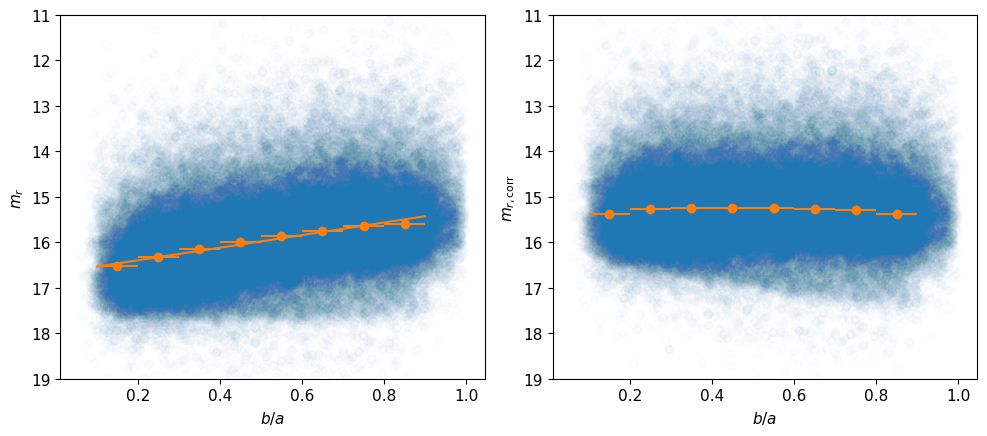

In [14]:
#- Kelly applies an empirical fit to the internal dust in each galaxy. Steps:
#   1. Apply "known" corrections (k-correction, MW dust).
#   2. Fit m_r_corr (corrected) vs spiral b/a
#   3. Zero out this linear dependence.

#- Set up a binned data set and perform the fit
ba_bins = np.arange(0.1,1,0.1)
ba = 0.5*(ba_bins[1:] + ba_bins[:-1])
ba_err = 0.5*np.diff(ba_bins)
m_r_median = np.median(loa['R_MAG_SB26_tmp'])
m_r, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], statistic='median', bins=ba_bins)
n_bin, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], statistic='count', bins=ba_bins)
m_r_err, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], statistic='std', bins=ba_bins)
m_r_err /= np.sqrt(n_bin)

linear_fit = lambda coeff, x: coeff[0]*x + coeff[1]
model = Model(linear_fit)
data = RealData(ba, m_r - m_r_median, sx=ba_err, sy=m_r_err)
odr = ODR(data, model, beta0=[1, 1])

result = odr.run()
coeff = result.beta
coeff_err = result.sd_beta
print('Best fit:    ', coeff)
print('uncertainty: ', coeff_err)

fig, axes = plt.subplots(1,2, figsize=(10,4.5), tight_layout=True, sharex=True)#, sharey=True)
ax = axes[0]
ax.scatter(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], alpha=0.01)
ax.errorbar(ba, m_r, xerr=ba_err, yerr=m_r_err, fmt='o', color='tab:orange')
ax.plot(ba_bins, coeff[0]*ba_bins + coeff[1] + m_r_median, color='tab:orange')
ax.set(ylim=(19, 11),
       ylabel='$m_{r}$',
       xlabel='$b/a$');

#- Compute the internal dust correction
A_int, A_int_err = tfpc.internal_dust(loa['BA_ratio'].values, coeff, coeff_err)

ax = axes[1]
ax.scatter(loa['BA_ratio'], loa['R_MAG_SB26_tmp'] - A_int, alpha=0.01)
m_r, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'] - A_int, statistic='median', bins=ba_bins)
ax.errorbar(ba, m_r, xerr=ba_err, yerr=m_r_err, fmt='o', color='tab:orange')
ax.set(ylim=(19, 11),
       ylabel='$m_{r,\mathrm{corr}}$',
       xlabel='$b/a$')

# fig.savefig('tfr_mock_internal_dust_correction.png', dpi=150);

#- Update the r-band magnitudes
loa['R_MAG_SB26_CORR'] = loa['R_MAG_SB26_tmp'] - A_int
loa['R_MAG_SB26_ERR_CORR'] = np.sqrt(loa['R_MAG_SB26_ERR_tmp']**2 + A_int_err**2)

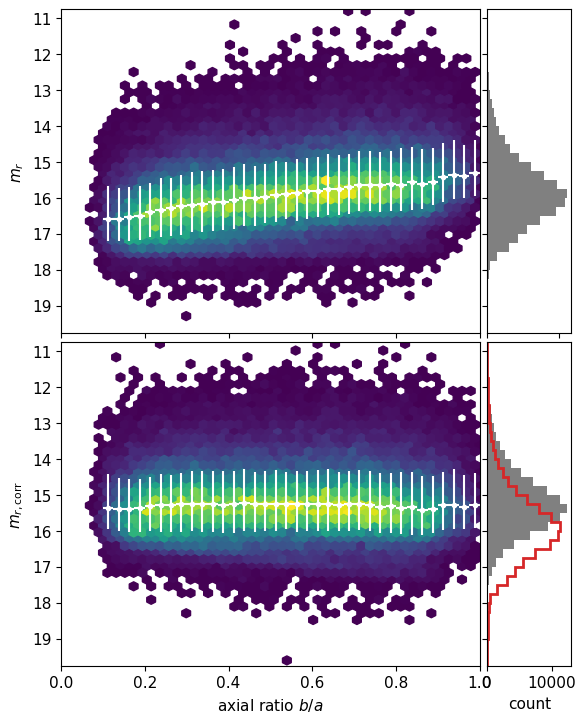

In [15]:
fig, axes = plt.subplots(2,2, figsize=(6,7.5),
                         gridspec_kw={'hspace':0.03, 'wspace':0.0295, 'width_ratios':[5,1]})

# m_r_bins = np.arange(19.75, 10.5, -0.25)
m_r_bins = np.arange(10.75, 20, 0.25)
ba_bins = np.arange(0.1, 1 + 0.025, 0.025)
ba = 0.5*(ba_bins[1:] + ba_bins[:-1])
ba_err = 0.5*np.diff(ba_bins)
m_r_median = np.median(loa['R_MAG_SB26_tmp'])
m_r, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], statistic='median', bins=ba_bins)
n_bin, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], statistic='count', bins=ba_bins)
m_r_err, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], statistic='std', bins=ba_bins)
m_r_err_lo, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], statistic=lambda x: np.percentile(x, [16]), bins=ba_bins)
m_r_err_hi, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], statistic=lambda x: np.percentile(x, [84]), bins=ba_bins)
# m_r_err /= np.sqrt(n_bin)

ax = axes[0,0]
ax.hexbin(loa['BA_ratio'], loa['R_MAG_SB26_tmp'], gridsize=(45,30), cmap='viridis', mincnt=2)
ax.errorbar(ba, m_r, xerr=ba_err, yerr=[m_r - m_r_err_lo, m_r_err_hi - m_r], fmt='.', color='white')

ax.set(xlim=(0,1),
       ylim=(19.75,10.75),
       ylabel=r'$m_r$',
       xticklabels=[])

ax = axes[0,1]
ax.hist(loa['R_MAG_SB26_tmp'], bins=m_r_bins, orientation='horizontal', color='gray')
ax.set(ylim=(19.75,10.75),
       yticklabels=[],
       xticklabels=[])

m_r, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp']  - A_int, statistic='median', bins=ba_bins)
n_bin, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp']  - A_int, statistic='count', bins=ba_bins)
m_r_err, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp']  - A_int, statistic='std', bins=ba_bins)
m_r_err_lo, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp']  - A_int, statistic=lambda x: np.percentile(x, [16]), bins=ba_bins)
m_r_err_hi, _, _ = binned_statistic(loa['BA_ratio'], loa['R_MAG_SB26_tmp']  - A_int, statistic=lambda x: np.percentile(x, [84]), bins=ba_bins)

ax = axes[1,0]
ax.hexbin(loa['BA_ratio'], loa['R_MAG_SB26_tmp'] - A_int, gridsize=(45,30), cmap='viridis', mincnt=2)
ax.errorbar(ba, m_r, xerr=ba_err, yerr=[m_r - m_r_err_lo, m_r_err_hi - m_r], fmt='.', color='white')

ax.set(xlim=(0,1),
       ylim=(19.75,10.75),
       xlabel=r'axial ratio $b/a$',
       ylabel=r'$m_{r,\mathrm{corr}}$')

ax = axes[1,1]
ax.hist(loa['R_MAG_SB26_tmp'] - A_int, bins=m_r_bins, orientation='horizontal', color='gray')
ax.hist(loa['R_MAG_SB26_tmp'], bins=m_r_bins, orientation='horizontal', histtype='step', lw=2, color='tab:red')
ax.set(ylim=(19.75,10.75),
       yticklabels=[],
       xlabel='count')

fig.subplots_adjust(left=0.1, right=0.95, top=0.95, bottom=0.075)
fig.savefig('TF_mock_syst_corr.png', dpi=200)

## BGS Mock Catalog

Read in one of the mock catalog files and cross-match to loa.

In [16]:
#- There are 25 BGS mocks and (usually) 27 realizations per mock.
#  Pick one, it doesn't matter which.
mockfiles = sorted(glob(os.path.join(pvpath, 'mocks/BGS_base/v0.5/iron/BGS_PV_AbacusSummit_base*.hdf5')))
n_mock = len(mockfiles)
# mockfile = mockfiles[np.random.randint(n_mock)]
mockfile = mockfiles[1]

print(f'Picked mock file {os.path.basename(mockfile)}.')

Picked mock file BGS_PV_AbacusSummit_base_c000_ph000_r001_z0.11.dat.hdf5.


In [17]:
#- Fill the catalog as a dictionary and convert to a Pandas table.
#  Here we follow the I/O from the FP generator (thanks Cullan).
mock = {}
with h5py.File(mockfile, 'r') as f:
    for key in f.keys():
        if key == 'vel':
            #- Pack the galaxy velocities into labeled vx, vy, vz
            mock['vx'] = f['vel'][:,0]
            mock['vy'] = f['vel'][:,1]
            mock['vz'] = f['vel'][:,2]
        else:
            mock[key] = f[key][()]

        # convert strings to unicode
        if key == 'survey' or key == 'program':
            mock[key] = mock[key].astype('U')

    #- Convert to a pandas table
    mock = pd.DataFrame.from_dict(mock)

    #- Merge with loa on 4 keywords
    mock = mock.merge(loa, how='inner', on=['targetid', 'survey', 'program', 'healpix'])

In [18]:
mock.keys()

Index(['Y1_COMP', 'Y3_COMP', 'Y5', 'abs_mag', 'app_mag', 'col', 'col_obs',
       'dec', 'halo_mass', 'healpix', 'is_cen', 'is_res', 'program', 'ra',
       'survey', 'targetid', 'vx', 'vy', 'vz', 'zcos', 'zobs', 'target_dec',
       'target_ra', 'z', 'zerr', 'zwarn', 'morphtype', 'sersic', 'mag_g',
       'mag_r', 'mag_z', 'uncor_radius', 'BA_ratio', 'circ_radius',
       'circ_radius_err', 'SGA_id', 'radius_SB25', 'inbasiccuts',
       'has_corrupt_phot', 'deltachi2', 'mag_err_g', 'mag_err_z', 'mag_err_r',
       'SGA_ra', 'SGA_dec', 'D26', 'G_MAG_SB26', 'G_MAG_SB26_ERR',
       'R_MAG_SB26', 'R_MAG_SB26_ERR', 'Z_MAG_SB26', 'Z_MAG_SB26_ERR',
       'photsys', 'G_MAG_SB26_tmp', 'G_MAG_SB26_ERR_tmp', 'R_MAG_SB26_tmp',
       'R_MAG_SB26_ERR_tmp', 'Z_MAG_SB26_tmp', 'Z_MAG_SB26_ERR_tmp',
       'R_MAG_SB26_CORR', 'R_MAG_SB26_ERR_CORR'],
      dtype='object')

In [19]:
mock

,Y1_COMP,Y3_COMP,Y5,abs_mag,app_mag,col,col_obs,dec,halo_mass,healpix,...,Z_MAG_SB26_ERR,photsys,G_MAG_SB26_tmp,G_MAG_SB26_ERR_tmp,R_MAG_SB26_tmp,R_MAG_SB26_ERR_tmp,Z_MAG_SB26_tmp,Z_MAG_SB26_ERR_tmp,R_MAG_SB26_CORR,R_MAG_SB26_ERR_CORR
0,1.000000,0.991803,True,-21.603735,16.064020,0.973818,1.000261,-0.999080,6.546589e+12,11943,...,0.020302,N,16.905313,0.037406,15.946197,0.031360,15.482358,0.030668,15.613675,0.037850
1,0.000000,0.962963,True,-22.974319,14.690473,0.943890,0.969189,4.955850,1.250601e+14,19362,...,0.017098,S,15.643840,0.038922,14.741572,0.027936,14.103924,0.022183,14.288080,0.040197
2,1.000000,1.000000,True,-20.328584,17.335948,0.754470,0.772327,4.141360,1.098831e+12,9063,...,0.040119,S,17.773587,0.047886,17.003483,0.042496,16.381809,0.041635,15.922955,0.080923
3,0.992857,0.992857,True,-22.095708,15.565224,0.963012,0.988384,-2.295285,3.791707e+13,8866,...,0.005774,S,16.552565,0.026155,15.584555,0.018091,14.904470,0.011323,15.470892,0.019487
4,1.000000,1.000000,True,-20.940196,16.710539,0.752585,0.769231,-2.161120,3.737292e+12,19996,...,0.010283,S,17.505536,NaN,16.904010,NaN,16.461705,NaN,16.760606,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
460957,0.845070,0.964789,True,-20.442594,17.215514,1.041612,1.067414,1.054418,1.092504e+12,11953,...,0.050015,N,17.862318,0.047117,16.839665,0.048677,16.082473,0.054987,15.780489,0.083226
460958,0.993506,1.000000,True,-20.977689,16.686527,0.941542,0.966701,-5.495919,2.952714e+12,27655,...,0.012371,S,17.607585,0.025481,16.652254,0.019910,16.057708,0.015125,16.315652,0.029269
460959,0.609023,0.969925,True,-21.044177,16.615062,0.952042,0.976926,1.892966,4.370017e+12,27655,...,0.012371,S,17.607585,0.025481,16.652254,0.019910,16.057708,0.015125,16.315652,0.029269
460960,0.958333,1.000000,True,-21.492587,16.173641,1.003167,1.029903,-2.016671,1.960813e+13,25531,...,0.013396,S,17.111787,0.032928,16.114706,0.024078,15.428282,0.017762,16.000786,0.025149


### Apply TF Selection Cuts

Here apply the late-type galaxy cuts defined in *Target Selection for the DESI Peculiar Velocity Survey*, C. Saulder+, MNRAS 525:1106, 2023. Note that several cuts are the complement of the early-type cuts for the FP sample.

In [20]:
mock_selection = {
    'basic cuts' : 0,
    # '0.03 < z < 0.105' : 0,
    'b/a < cos(25°)' : 0,
    'morphtype' : 0,
    'NaN' : 0
}

#- Apply target selection
print(f'Size of cross-matched loa+mock catalog ..{len(mock):.>20d}')

#- Drop data that doesn't pass the photometric cuts
select = (mock['inbasiccuts'] == 0) | (mock['has_corrupt_phot'] == 1)
mock = mock.drop(mock[select].index)
mock_selection['basic cuts'] = len(mock)
print(f'Size after photometric cuts .........{len(mock):.>20d}')

#- Redshift range cut: remove?
# select = (mock['zobs'] > 0.03) & (mock['zobs'] <= 0.105)
# mock = mock[select]
# mock_selection['0.03 < z < 0.105'] = len(mock)
# print(f'Redshift selection: 0.03 < z < 0.105 {len(mock):.>20d}')

#- B/A ratio cut:
select = mock['BA_ratio'] < np.cos(np.radians(25))
mock = mock[select]
mock_selection['b/a < cos(25°)'] = len(mock)
print(f'Ratio b/a < cos(25 deg) .............{len(mock):.>20d}')

#- Morphology cuts:
select = (mock['morphtype'] == 'EXP') | ((mock['morphtype'] == 'SER') & (mock['sersic'] <= 2))
mock = mock[select]
mock_selection['morphtype'] = len(mock)
print(f'Morphology cuts: ....................{len(mock):.>20d}')

#- Drop any rows with NaN
mock = mock.dropna()
mock_selection['NaN'] = len(mock)
print(f'Drop NaN ............................{len(mock):.>20d}')

Size of cross-matched iron+mock catalog ................460962
Size after photometric cuts .......................460765
Ratio b/a < cos(25 deg) ...........................445228
Morphology cuts: ..................................237495
Drop NaN ..........................................203127


/tmp/ipykernel_1377377/3164248107.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(names, rotation=45, ha='right')


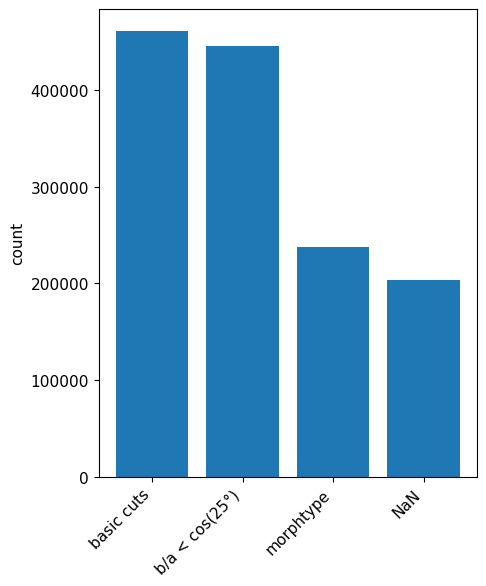

In [21]:
names = list(mock_selection.keys())
values = list(mock_selection.values())

fig, ax = plt.subplots(1, 1, figsize=(5,6), tight_layout=True)
bars = ax.bar(names, values)
ax.set_xticklabels(names, rotation=45, ha='right')
# ax.bar_label(bars, fmt='%d')
ax.set(ylabel='count');#, yscale='log', ylim=[1e3,1.2e4])
fig.set_facecolor('none')
# fig.savefig('tfr_mock_cuts.png', dpi=150)

## Compute TFR Quantities

Assign a rotational velocity using the data. Then use this to infer $M_r$ using the calibrated TFR.

### Set up the Cosmology

Use a flat-$\Lambda$CDM fiducial cosmology with $H_0\equiv100$ km/s/Mpc and $\Omega_m=0.3151$.

In [22]:
h = 1
cosmology = FlatLambdaCDM(H0=100*h, Om0=0.3151)

### Current Y3 TFR Best Fit

TF Y3 best-fit parameters and covariances, corresponding to v3 of the TF Y3 catalog. This comes from the TFR calibration using redshift bins of width 0.005 from z=0.01 to z=0.10. We fit for 

$$
M_r = a \log_{10}{\left(\frac{V_\mathrm{rot}}{V_0}\right)} + b_{i}
$$

with intrinsic scatter $\sigma$ along the magnitude axis. 

The parameter vector includes the TFR slope $a$, bin intercepts $\{b_i\}$, and intrinsic scatter $\sigma$.

In [115]:
with open('/global/cfs/cdirs/desi/science/td/pv/tfgalaxies/Y3/cov_ab_loa_jointTFR_ellipse_v3.pickle', 'rb') as tfr_file:
    cov_ab, tfr_samples, logV0, zmin, zmax, dz, zbins = pickle.load(tfr_file)

tf_par = np.median(tfr_samples, axis=1)
a, b, sigma = tf_par[0], tf_par[1:-1], tf_par[-1]

### Current TFR Catalog

Read in the TFR catalog to sample uncertainties in $V_\mathrm{rot}$.

In [24]:
tfr_version = 'v3'
tfrcatfile = os.path.join(pvpath, f'tfgalaxies/Y3/DESI-DR2_TF_pv_cat_{tfr_version}.fits')
tfrcat = Table.read(tfrcatfile)
tfr_params = fits.open(tfrcatfile)
#- Set minimum velocity uncertainty to 7 km/s.
# lowverr = tfrcat['V_0p4R26_ERR'] < 7.
# tfrcat['V_0p4R26_ERR'][lowverr] = 7.

tfrcat['logv_rot'] = np.log10(tfrcat['V_0p4R26'])
tfrcat['logv_rot_err'] = 0.434*tfrcat['V_0p4R26_ERR'] / tfrcat['V_0p4R26']

tfrcat = tfrcat['Z_DESI', 'Z_DESI_CMB', 'D26', 'R_MAG_SB26_CORR', 'R_MAG_SB26_ERR_CORR', 'R_ABSMAG_SB26', 'R_ABSMAG_SB26_ERR', 'LOGDIST', 'LOGDIST_ERR','GOOD_MORPH', 'MU_ZCMB', 'MU_ZCMB_ERR', 'V_0p4R26', 'V_0p4R26_ERR', 'logv_rot', 'logv_rot_err', 'MAIN'].to_pandas()
tfrcat

,Z_DESI,Z_DESI_CMB,D26,R_MAG_SB26_CORR,R_MAG_SB26_ERR_CORR,R_ABSMAG_SB26,R_ABSMAG_SB26_ERR,LOGDIST,LOGDIST_ERR,GOOD_MORPH,MU_ZCMB,MU_ZCMB_ERR,V_0p4R26,V_0p4R26_ERR,logv_rot,logv_rot_err,MAIN
0,0.083614,0.083405,0.446012,17.076032,0.100760,-20.044143,0.100762,0.008504,0.093879,True,37.120175,0.000731,136.403203,12.846762,2.134825,0.040875,True
1,0.095547,0.095839,0.688028,15.567141,0.136495,-21.872853,0.136498,0.032958,0.088169,True,37.439994,0.000929,242.317328,16.546343,2.384384,0.029635,True
2,0.080989,0.081623,0.417579,17.117764,0.137757,-19.952875,0.137759,0.054550,0.095123,True,37.070639,0.000744,122.100024,11.083695,2.086716,0.039397,True
3,0.099164,0.099107,0.382016,16.435343,0.096863,-21.082143,0.096865,-0.114333,0.083336,True,37.517486,0.000738,237.829528,13.626208,2.376266,0.024866,True
4,0.044002,0.045083,0.495681,17.340004,0.112013,-18.386444,0.112022,-0.005210,0.090258,True,35.726448,0.001370,82.135388,6.545710,1.914530,0.034587,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35661,0.171868,0.172100,0.513374,17.886860,0.185103,-20.928437,0.185104,-0.088640,0.088525,True,38.815298,0.000409,215.795108,11.927193,2.334042,0.023988,True
35662,0.118856,0.119145,0.362001,17.821988,0.087352,-20.123678,0.087359,0.072189,0.132817,True,37.945667,0.001133,123.960975,22.357563,2.093285,0.078276,False
35663,0.133826,0.134099,0.454465,17.511913,0.178973,-20.711118,0.178974,-0.004355,0.103056,True,38.223031,0.000701,173.164853,18.521233,2.238460,0.046419,True
35664,0.056664,0.056845,0.569711,16.999429,0.142214,-19.248527,0.142219,-0.001025,0.086088,True,36.247956,0.001150,107.868386,6.314341,2.032894,0.025405,True


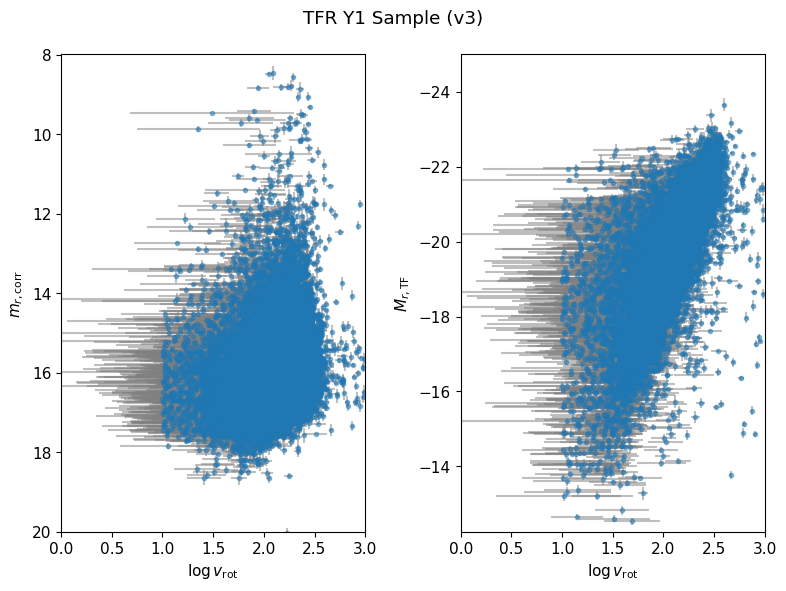

In [25]:
fig, axes = plt.subplots(1,2, figsize=(8,6), tight_layout=True, sharex=True)

ax = axes[0]
ax.errorbar(tfrcat['logv_rot'], tfrcat['R_MAG_SB26_CORR'],
             xerr=tfrcat['logv_rot_err'],
             yerr=tfrcat['R_MAG_SB26_ERR_CORR'],
             fmt='.', 
             alpha=0.5, 
             ecolor='gray')

ax.set(xlim=(0,3),
       xlabel=r'$\log{v_\mathrm{rot}}$',
       ylabel=r'$m_{r,\mathrm{corr}}$',
       ylim=(20,8))

ax = axes[1]
ax.errorbar(tfrcat['logv_rot'], tfrcat['R_ABSMAG_SB26'],
             xerr=tfrcat['logv_rot_err'],
             yerr=tfrcat['R_ABSMAG_SB26_ERR'],
             fmt='.', 
             alpha=0.5, 
             ecolor='gray')

ax.set(xlim=(0,3),
       xlabel=r'$\log{v_\mathrm{rot}}$',
       ylabel=r'$M_{r,\mathrm{TF}}$',
       ylim=(-12.25, -25))

fig.suptitle(f'TFR Y3 Sample ({tfr_version})')
fig.set_facecolor('none');
# fig.savefig('tfr_y1_sample.png', dpi=180);

### Generate Absolute Magnitudes for TFR Fitting

Procedure:
1. Calculate $M_{r,\mathrm{cos}}$ using $z_\mathrm{cos}$ from the mocks. This explicitly excludes mock peculiar velocities.
1. Compute distance moduli $\mu$ for each *observed* redshift in the mocks, $z_\mathrm{obs}$.
1. Compute $M_{r,\mathrm{obs}}$ using $m_{r,\mathrm{SB26}}$ from cross-matched from data and the generated $\mu$.
1. Scatter $\log{V_\mathrm{rot}}$ by binning the Y3 data in magnitude ($M_{r,\mathrm{cos}}$), computing the $\log{v_\mathrm{rot}}$ CDF in each bin, and randomly sampling new values.

In [26]:
#- Use distmod with cosmological redshifts to compute a "true" absolute magnitude M_r(SB26).
#  Then compute a central value for rotational velocity using this "true" magnitude.
Mr_cos = mock['R_MAG_SB26_CORR'] - cosmology.distmod(mock['zcos']).to_value('mag')

#- Compute an observed magnitude based on the PVs in the mock catalog.
mu_obs_mock = cosmology.distmod(mock['zobs']).to_value('mag')
mock['MU_OBS_MOCK'] = mu_obs_mock
Mr_obs_mock = (mock['R_MAG_SB26_CORR'] - mu_obs_mock).to_numpy()
Mr_obs_err_mock = mock['R_MAG_SB26_ERR_CORR'].to_numpy()

#- Bin R_ABSMAG_SB26. Merge any bins with < 50 datapoints, working from the ends of the magnitude range.
bins = np.arange(-26, -12 + 0.05, 0.05)
M_r_bins = [bins[0]]
for k in np.arange(1, len(bins)):
    select = (tfrcat['R_ABSMAG_SB26'] > M_r_bins[-1]) & (tfrcat['R_ABSMAG_SB26'] <= bins[k])    
    if np.sum(select) >= 50:
        M_r_bins.append(bins[k])
M_r_bins.append(bins[-1])
N_bins = len(M_r_bins)

print(np.histogram(tfrcat['R_ABSMAG_SB26'], M_r_bins))

#- Loop through the magnitude bins and regenerate log(v_rot) by resampling the data.
#  Try to reduce resampling effects by using a smoothed version of the CDF of log(v_rot).
logvrot_mock = np.zeros_like(Mr_obs_mock)

use_weighted_fit = True

for k in tqdm(np.arange(0, N_bins-1)):
    # # TEST
    # if k > 5*N_bins//9:
    #     break
    
    M_r_min, M_r_max = M_r_bins[k], M_r_bins[k+1]

    #- Select TFR velocity data in this magnitude bin and compute the CDF of log(v_rot).
    i = (tfrcat['R_ABSMAG_SB26'] > M_r_min) & (tfrcat['R_ABSMAG_SB26'] <= M_r_max)
    logvrot_slice = tfrcat['logv_rot'][i].to_numpy()
    logvrot_err_slice = tfrcat['logv_rot_err'][i].to_numpy()

    if use_weighted_fit:
        #- Attempt to build a weighted CDF
        logvrot_bins = np.arange(1, 3.01, 0.01)
        logvrot_pdf_wt, logv_bins = np.histogram(logvrot_slice, bins=logvrot_bins, 
                                                 weights=np.ones_like(logvrot_err_slice)
                                                 # weights=1/logvrot_err_slice**2
                                                )
        logvrot_cdf = np.cumsum(logvrot_pdf_wt) / np.sum(logvrot_pdf_wt)
        
        logvrot_slice = 0.5*(logvrot_bins[1:] + logvrot_bins[:-1])

        #- Keep only the unique elements in the list
        idx = np.cumsum([len(list(g)) for k, g in groupby(logvrot_cdf)])[:-1]
        logvrot_cdf = logvrot_cdf[idx]
        logvrot_slice = logvrot_slice[idx]
        # print(logvrot_cdf.shape, logvrot_slice.shape)
    else:
        #- Default to the unweighted CDF
        logvrot_cdf = np.cumsum(logvrot_slice) / np.sum(logvrot_slice)

    #- Select mock data in this magnitude bin.
    j = (Mr_cos > M_r_min) & (Mr_cos <= M_r_max)
    # j = (Mr_obs_mock > M_r_min) & (Mr_obs_mock <= M_r_max)
    N_mock_slice = np.sum(j)
    un = np.random.uniform(size=N_mock_slice)
    logvrot_mock_slice = csaps(logvrot_cdf, np.sort(logvrot_slice), un).values
    logvrot_mock[j] = logvrot_mock_slice

    #- Apply a velocity cut of 10 to 1000 km/s.
    #  Regenerate any velocities that fall outside the valid range.
    #  Note that an intermediate variable is needed to manage the array slicing.
    bad_vrot = (logvrot_mock[j] < 1) | (logvrot_mock[j] > 3)
    while np.any(bad_vrot):
        N_regen = np.sum(bad_vrot)
        uni = np.random.uniform(size=N_regen)
        logvrot_mock_regen = logvrot_mock[j]
        logvrot_mock_regen[bad_vrot] = csaps(logvrot_cdf, np.sort(logvrot_slice), uni).values
        logvrot_mock[j] = logvrot_mock_regen
        bad_vrot = (logvrot_mock[j] < 1) | (logvrot_mock[j] > 3)

# - Finally, match mock values against the Y3 data to assign uncertainties on logvrot_mock and Mr_obs_mock.
#  Many ways to do this... here just copy the FP approach of grabbing the nearest neighbor in (log v, M_r)
#  from data and taking its uncertainty.
search_tree = KDTree(np.c_[tfrcat['logv_rot'], tfrcat['R_ABSMAG_SB26']])
search_tree.query([1.5, -20])
_, idx = search_tree.query([[x, y] for (x,y) in zip(logvrot_mock, Mr_obs_mock)])

logvrot_err_mock = tfrcat['logv_rot_err'][idx].to_numpy()
Mr_obs_err_mock = mock['R_MAG_SB26_ERR_CORR'].to_numpy()

mock['LOGVROT_MOCK'] = logvrot_mock
mock['LOGVROT_ERR_MOCK'] = logvrot_err_mock
mock['R_ABSMAG_SB26_MOCK'] = Mr_obs_mock
mock['R_ABSMAG_SB26_ERR_MOCK'] = Mr_obs_err_mock

(array([ 63,  53,  55,  97,  54,  63,  83,  94, 111, 118, 133, 158, 165,
       197, 216, 230, 252, 298, 283, 320, 347, 365, 399, 443, 427, 445,
       524, 492, 521, 531, 544, 576, 590, 625, 588, 633, 639, 611, 626,
       646, 638, 593, 558, 592, 597, 624, 640, 587, 596, 572, 574, 558,
       562, 490, 532, 518, 496, 531, 471, 446, 479, 411, 396, 381, 389,
       371, 337, 347, 322, 332, 321, 294, 311, 281, 250, 252, 256, 232,
       224, 212, 181, 197, 219, 165, 181, 193, 184, 157, 151, 155, 126,
       155, 127, 102, 121, 104, 111, 116,  90,  93,  77,  65,  77,  63,
        74,  67,  62,  58, 102,  75,  86,  71,  57,  51,  57,  65,  58,
        57,  51,  51,  52,  55,  50,  51,  17]), array([-26.  , -22.6 , -22.45, -22.35, -22.25, -22.2 , -22.15, -22.1 ,
       -22.05, -22.  , -21.95, -21.9 , -21.85, -21.8 , -21.75, -21.7 ,
       -21.65, -21.6 , -21.55, -21.5 , -21.45, -21.4 , -21.35, -21.3 ,
       -21.25, -21.2 , -21.15, -21.1 , -21.05, -21.  , -20.95, -20.9 ,
       -20.85, -20

100%|██████████| 125/125 [00:00<00:00, 251.85it/s]


In [27]:
# k = 2*N_bins//3
# M_r_min, M_r_max = M_r_bins[k], M_r_bins[k+1]

# #- Select TFR velocity data in this magnitude bin and compute the CDF of log(v_rot).
# i = (tfrcat['R_ABSMAG_SB26'] > M_r_min) & (tfrcat['R_ABSMAG_SB26'] <= M_r_max)
# logvrot_slice = tfrcat['logv_rot'][i].to_numpy()
# logvrot_err_slice = tfrcat['logv_rot_err'][i].to_numpy()
# logvrot_cdf = np.cumsum(logvrot_slice) / np.sum(logvrot_slice)

# fig, axes = plt.subplots(1, 4, figsize=(16,4), tight_layout=True)

# logvrot_bins = np.arange(1, 3.05, 0.05)

# ax = axes[0]
# ax.hist(logvrot_slice, bins=logvrot_bins)
# ax.set(xlabel=r'$\log{v_\mathrm{rot}}$',
#        ylabel=r'count',
#        title='slice histogram')

# ax = axes[1]
# logvrot_pdf_wt, logv_bins, _ = ax.hist(logvrot_slice, bins=logvrot_bins, weights=1/logvrot_err_slice**2)
# newcdf_wt = np.cumsum(logvrot_pdf_wt) / np.sum(logvrot_pdf_wt)
# ax.set(xlabel=r'$\log{v_\mathrm{rot}}$',
#        title='weighted slice histogram')

# ax = axes[2]
# logvrot_gen = np.random.multivariate_normal(mean=logvrot_slice, cov=np.diag(logvrot_err_slice**2), size=1000).flatten()
# logvrot_pdf_rsmpl, logv_bins, _ = ax.hist(logvrot_gen, bins=logvrot_bins)
# newcdf_rsmpl = np.cumsum(logvrot_pdf_rsmpl) / np.sum(logvrot_pdf_rsmpl)
# ax.set(xlabel=r'$\log{v_\mathrm{rot}}$',
#        title='resampled histogram')

# ax = axes[3]
# ax.plot(np.sort(logvrot_slice), logvrot_cdf, label='unweighted CDF')
# ax.plot(logv_bins[:-1], newcdf_wt, label='weighted CDF')
# ax.plot(logv_bins[:-1], newcdf_rsmpl, label='resampled CDF')
# ax.set(xlabel=r'$\log{v_\mathrm{rot}}$',
#        title='CDF')
# l = ax.legend(loc='upper left', fontsize=10)

#### Apply Outlier Cuts

We define the main cosmology sample to be the objects that fall inside the best-fit ellipse of their respective redshift bins. We read in the best fit ellipse parameters from the DR2 data.

In [38]:
def downsample(mock, size=100):
    """Randomly downsample a mock catalog, without replacement, to some size.

    Parameters
    ----------
    mock: pandas.DataFrame
        Pandas table with a mock catalog.
    size: int
        Size of the final downsampled catalog.

    Returns
    -------
    newmock: pandas.DataFrame
        Downsampled Pandas table.
    """
    Nmock = len(mock)
    idx_downsample = np.random.choice(Nmock, size, replace=False)
    return mock.iloc[idx_downsample]


def ellipse_boolean(x, y, mean, cov, n_std=2):
    """
    Determine which points are outside of the ellipse defined by (mean, cov, n_std).

    Parameters
    ----------
    x, y : array-like
        Coordinates of points to test
    mean : array-like, shape (2,)
        Ellipse center
    cov : array-like, shape (2, 2)
        Ellipse covariance matrix
    n_std : float
        Number of standard deviations defining the ellipse

    Returns
    -------
    outlier_boolean : ndarray of bool
        True for points outside the ellipse
    """
    X = np.vstack([x, y]).T
    # mean = np.asarray(mean)
    # cov = np.asarray(cov)

    # Mahalanobis distance squared
    diff = X - mean
    inv_cov = np.linalg.inv(cov)
    mahal_sq = np.einsum('ij,jk,ik->i', diff, inv_cov, diff)

    boolean = mahal_sq > n_std**2
    return ~boolean

def mag_ellipse_boolean(z, x, y, ellipse_vals, n_std, absmag_cat):
    outlier_boolean = np.zeros(len(x), dtype=bool)
    zbin_indices = np.digitize(z, zbins, right=True)
    
    ##first bin and last bin
    for i in {0,max(zbin_indices)}:
        bin_mask = (zbin_indices == 0)
        mean = [ellipse_vals[i][0], ellipse_vals[i][1]]
        cov = [[ellipse_vals[i][2], ellipse_vals[i][3]],[ellipse_vals[i][4],ellipse_vals[i][5]]]
        # Outliers within each magnitude bun
        outlier_bin = ellipse_boolean(x[bin_mask], absmag_cat[bin_mask], mean, cov, n_std)
        # Write results back into global array
        outlier_boolean[bin_mask] = outlier_bin
        
    for i in range(1, len(zbins)):
    # for i in range(1, len(zbins)+1):
        bin_mask = (zbin_indices == i)

        mean = [ellipse_vals[i][0], ellipse_vals[i][1]]
        cov = [[ellipse_vals[i][2], ellipse_vals[i][3]],[ellipse_vals[i][4],ellipse_vals[i][5]]]

        # Outliers within each magnitude bun
        outlier_bin = ellipse_boolean(x[bin_mask], y[bin_mask], mean, cov, n_std)

        # Write results back into global array
        outlier_boolean[bin_mask] = outlier_bin
    return outlier_boolean

def plot_ellipse(mean, cov, ax, n_std=2.0, **kwargs):
    """
    Draw a confidence ellipse from mean and covariance.
    n_std=2 ~ 95% for 2D
    """
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = eigvals.argsort()[::-1]
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]

    angle = np.degrees(np.arctan2(*eigvecs[:,0][::-1]))

    width, height = 2 * n_std * np.sqrt(eigvals)

    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=angle,
        **kwargs
    )
    ax.add_patch(ellipse)

In [34]:
#### Read in the best-fit ellipse parameters
ellipse_params = Table.read('/global/cfs/cdirs/desi/science/td/pv/tfgalaxies/Y3/TF_Y3_ellipse_fit_mr_0p01-0p1.fits')

#### Plot $M_{R,\mathrm{SB26}}$ for Mocks and TFR Data

Make a side-by-side comparison of the (downsampled) mock catalog and Y3 data.

Apply the quality cuts equally to both.

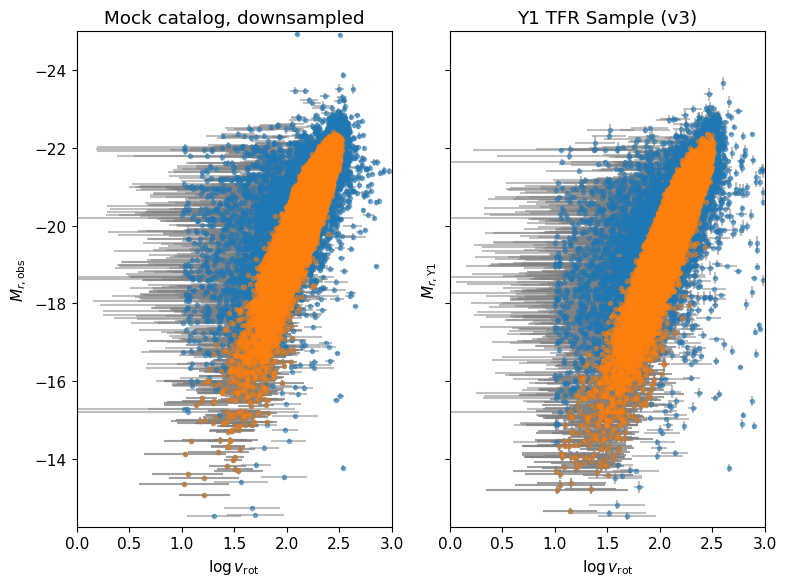

In [39]:
#- Plot Mr vs log(v_rot) for the various steps in the calculation.

fig, axes = plt.subplots(1,2, figsize=(8,6), tight_layout=True, sharex=True, sharey=True)

Ntfr = len(tfrcat)
mock_downsample = downsample(mock, Ntfr)

ax = axes[0]
ax.errorbar(mock_downsample['LOGVROT_MOCK'], mock_downsample['R_ABSMAG_SB26_MOCK'],
            xerr=mock_downsample['LOGVROT_ERR_MOCK'],
            yerr=mock_downsample['R_ABSMAG_SB26_ERR_MOCK'],
            fmt='.', 
            alpha=0.5, 
            ecolor='gray')


idx_mock_good = mag_ellipse_boolean(mock_downsample['zobs'], mock_downsample['LOGVROT_MOCK'], mock_downsample['R_MAG_SB26_CORR'],
                                    ellipse_params, n_std=ellipse_sigma, absmag_cat=mock_downsample['R_ABSMAG_SB26_MOCK'])

ax.errorbar(mock_downsample['LOGVROT_MOCK'][idx_mock_good], mock_downsample['R_ABSMAG_SB26_MOCK'][idx_mock_good],
             xerr=mock_downsample['LOGVROT_ERR_MOCK'][idx_mock_good],
             yerr=mock_downsample['R_ABSMAG_SB26_ERR_MOCK'][idx_mock_good],
             fmt='.', 
             alpha=0.5, 
             ecolor='gray')

ax.set(xlim=(0,3),
       xlabel=r'$\log{v_\mathrm{rot}}$',
       ylabel=r'$M_{r,\mathrm{obs}}$',
       ylim=(-12.25, -25),
       title=r'Mock catalog, downsampled')

ax = axes[1]
ax.errorbar(tfrcat['logv_rot'], tfrcat['R_ABSMAG_SB26'],
             xerr=tfrcat['logv_rot_err'],
             yerr=tfrcat['R_ABSMAG_SB26_ERR'],
             fmt='.', 
             alpha=0.5, 
             ecolor='gray')

# idx_tfr_goodv = alex_cuts_velocity(tfrcat, logv_name='logv_rot', distmod_name='MU_ZCMB')
# idx_tfr_notdwarf = alex_cuts_dwarf(tfrcat, rmag_name='R_MAG_SB26_CORR', distmod_name='MU_ZCMB')
# idx_tfr_good = idx_tfr_goodv & idx_tfr_notdwarf
idx_tfr_good = mag_ellipse_boolean(tfrcat['Z_DESI_CMB'], tfrcat['logv_rot'], tfrcat['R_MAG_SB26_CORR'],
                                   ellipse_params, n_std=ellipse_sigma, absmag_cat=tfrcat['R_ABSMAG_SB26'])

ax.errorbar(tfrcat['logv_rot'][idx_tfr_good], tfrcat['R_ABSMAG_SB26'][idx_tfr_good],
             xerr=tfrcat['logv_rot_err'][idx_tfr_good],
             yerr=tfrcat['R_ABSMAG_SB26_ERR'][idx_tfr_good],
             fmt='.', 
             alpha=0.5, 
             ecolor='gray')

ax.set(xlim=(0,3),
       xlabel=r'$\log{v_\mathrm{rot}}$',
       ylabel=r'$M_{r,\mathrm{Y1}}$',
       ylim=(-12.25, -25),
       title=f'Y3 TFR Sample ({tfr_version})');

fig.set_facecolor('none');
# fig.savefig('tfr_mock_mr_vs_logv.png', dpi=150);

In [40]:
mpl.rc('font', size=12)

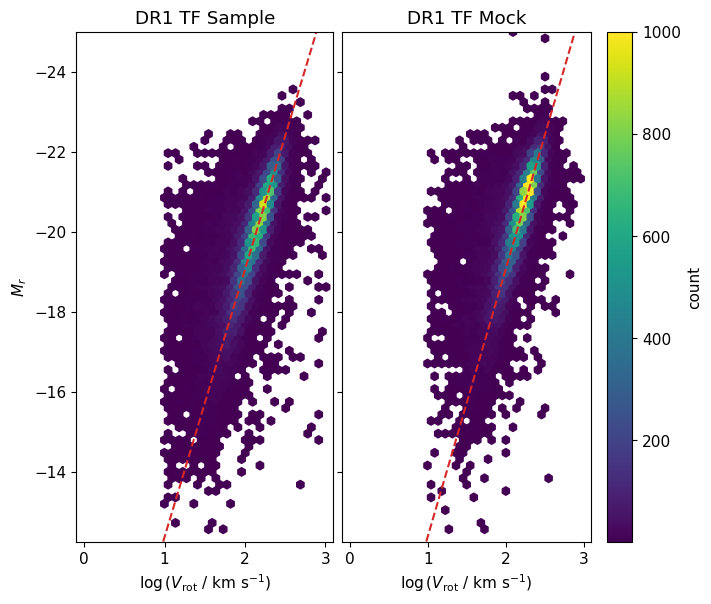

In [49]:
fig, axes = plt.subplots(1,2, figsize=(7,6), sharex=True, sharey=True,
                         gridspec_kw={'wspace':0.03, 'width_ratios':[0.825,1]})

ax = axes[0]
ax.hexbin(tfrcat['logv_rot'], tfrcat['R_ABSMAG_SB26'],
          cmap='viridis', mincnt=1, 
          vmin=1, vmax=1e3,
          gridsize=(35,40), extent=(-0.1, 3.1, -25, -12.25))
ax.set(xlim=(-0.1,3.1),
       xlabel=r'$\log{(V_\mathrm{rot}~/~\mathrm{km~s}^{-1})}$',
       ylabel=r'$M_{r}$',
       ylim=(-12.25, -25),
       title=f'DR2 TF Sample')# ({tfr_version})');

_log_v_rot = np.arange(-0.1, 3.05, 0.05)
b0 = -5.7
a0 = a
ax.plot(_log_v_rot, b0 + a0*_log_v_rot, ls='--', color='tab:red')

ax = axes[1]
h = ax.hexbin(mock_downsample['LOGVROT_MOCK'], mock_downsample['R_ABSMAG_SB26_MOCK'],
              cmap='viridis', mincnt=1, 
              vmin=1, vmax=1e3,
              gridsize=(35,40), extent=(-0.1, 3.1, -25, -12.25))
cb = fig.colorbar(h, ax=ax, label='count')

ax.set(xlim=(-0.1,3.1),
       xlabel=r'$\log{(V_\mathrm{rot}~/~\mathrm{km~s}^{-1})}$',
       # ylabel=r'$M_{r,\mathrm{Y3}}$',
       ylim=(-12.25, -25),
       title=f'DR2 TF Mock')

_log_v_rot = np.arange(-0.1, 3.05, 0.05)
b0 = -5.7
a0 = a
ax.plot(_log_v_rot, b0 + a0*_log_v_rot, ls='--', color='tab:red')

fig.subplots_adjust(left=0.1, right=0.925, top=0.95, bottom=0.1)
# fig.savefig('TF_mock_dr2_relation.png', dpi=200)

mpl.rc('font', size=11);

#### Apply Quality Cuts to the Full Mock Sample

In [50]:
idx_mock_good = mag_ellipse_boolean(mock['zobs'], mock['LOGVROT_MOCK'], mock['R_MAG_SB26_CORR'],
                                    ellipse_params, n_std=ellipse_sigma, absmag_cat=mock['R_ABSMAG_SB26_MOCK'])

print(np.sum(idx_mock_good), len(mock))

170580 203127


### Compute the Maximum Volume for each Galaxy

Since the SGA is size-limited, with $D_{26}>0.2'$, there is a maximum volume within which the galaxy could be located to be included in the SGA. Calculate the maximum volume to be used as a weight in the TFR calibration.

In [51]:
dist = cosmology.luminosity_distance(np.abs(mock['zobs']))
dist_max = cosmology.luminosity_distance(z=0.1)
d26_kpc = 2*dist.to('kpc') * np.tan(0.5*mock['D26'].values*u.arcmin)
mock_dist_max = 0.5*d26_kpc / np.tan(0.1*u.arcmin)
# surv_max = cosmology.luminosity_distance(z=0.2)

# mock['D26_kpc'] = 2*dist.to_value('kpc') * np.tan(0.5*mock['D26'].values*u.arcmin)
# mock['DIST_MAX'] = 0.5*mock['D26_kpc'].values / np.tan(0.1*u.arcmin)
# mock['MAX_VOL_FRAC'] = (1e-3 * mock['DIST_MAX'].values)**3 / dist_max.to_value('Mpc')**3
mock['MAX_VOL_FRAC'] = mock_dist_max.to('Mpc')**3 / dist_max.to('Mpc')**3

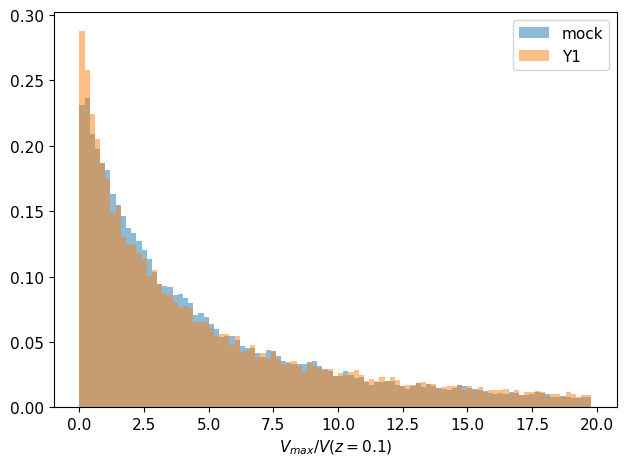

In [52]:
plt.figure(tight_layout=True)

loa_dist = cosmology.luminosity_distance(np.abs(tfrcat['Z_DESI'].values))
loa_d26kpc = 2*loa_dist.to('kpc') * np.tan(0.5*tfrcat['D26'].values*u.arcmin)
loa_dist_max = 0.5*loa_d26kpc / np.tan(0.1*u.arcmin)

plt.hist(mock['MAX_VOL_FRAC'], np.arange(0, 20, 0.2), density=True, alpha=0.5, label='mock')
plt.hist(loa_dist_max.to('Mpc')**3 / dist_max.to('Mpc')**3, np.arange(0, 20, 0.2), density=True, alpha=0.5, label='Y3')

plt.legend()

plt.xlabel('$V_{max}$/$V(z = 0.1)$');

### Fit the TFR and Compute Mock Distance Moduli

Fit $M_{r,\mathrm{obs,mock}}$ versus $\log{V_\mathrm{rot,mock}}$ to get a mock TFR.

Then compute the TF distance modulus as

$$
\mu_\mathrm{mock} = m_{r,\mathrm{SB_{26}}} - M_{r,\mathrm{obs,mock}},
$$

where the apparent magnitude is the quantity `R_MAG_SB26_CORR` used to compute magnitudes from the cosmological and observed redshift.

#### Create a Synthetic Data Set for TFR Fitting

In [53]:
mock_downsample = downsample(mock, Ntfr)

idx_mock_downsample_good = mag_ellipse_boolean(mock_downsample['zobs'], mock_downsample['LOGVROT_MOCK'], mock_downsample['R_MAG_SB26_CORR'],
                                    ellipse_params, n_std=ellipse_sigma, absmag_cat=mock_downsample['R_ABSMAG_SB26_MOCK'])

print(f'Nmock      = {len(mock_downsample):6d}\n'
      f'Nmock_cuts = {len(mock_downsample[idx_mock_downsample_good]):6d}\n'
      f'Ntfr       = {len(tfrcat):6d}\n'
      f'Ntfr_cuts  = {len(tfrcat[idx_tfr_good]):6d}')

Nmock      =  35666
Nmock_cuts =  30026
Ntfr       =  35666
Ntfr_cuts  =  28223


In [54]:
zbin_idx = np.digitize(mock_downsample['zobs'], zbins, right=True)
for i in range(len(zbins) + 1):
    if i == 0:
        print(f'{i:2d}  z <= {zbins[i]:0.3f}  {np.sum(zbin_idx == i):3d} galaxies')
    elif i == len(zbins):
        print(f'{i:2d}  z > {zbins[i-1]:0.3f}  {np.sum(zbin_idx == i):3d} galaxies')
    else:
        print(f'{i:2d}  {zbins[i-1]:0.3f} < z <= {zbins[i]:0.3f}  {np.sum(zbin_idx == i):3d} galaxies')

 0  z <= 0.010  534 galaxies
 1  0.010 < z <= 0.015  793 galaxies
 2  0.015 < z <= 0.020  1491 galaxies
 3  0.020 < z <= 0.025  1896 galaxies
 4  0.025 < z <= 0.030  2073 galaxies
 5  0.030 < z <= 0.035  2571 galaxies
 6  0.035 < z <= 0.040  2829 galaxies
 7  0.040 < z <= 0.045  2774 galaxies
 8  0.045 < z <= 0.050  2788 galaxies
 9  0.050 < z <= 0.055  2374 galaxies
10  0.055 < z <= 0.060  2203 galaxies
11  0.060 < z <= 0.065  2164 galaxies
12  0.065 < z <= 0.070  2057 galaxies
13  0.070 < z <= 0.075  1824 galaxies
14  0.075 < z <= 0.080  1756 galaxies
15  0.080 < z <= 0.085  1461 galaxies
16  0.085 < z <= 0.090  1190 galaxies
17  0.090 < z <= 0.095  867 galaxies
18  0.095 < z <= 0.100  771 galaxies
19  z > 0.100  1250 galaxies


In [55]:
# Downsample the mock catalog after cuts to 4200 galaxies.

no_use = (zbin_idx == 0) | (zbin_idx == len(zbins))
mock_downsample = downsample(mock_downsample[idx_mock_downsample_good & ~no_use], size=4200)

zbin_idx = np.digitize(mock_downsample['zobs'], zbins, right=True)
for i in range(len(zbins) + 1):
    if i == 0:
        print(f'{i:2d}  z <= {zbins[i]:0.3f}  {np.sum(zbin_idx == i):3d} galaxies')
    elif i == len(zbins):
        print(f'{i:2d}  z > {zbins[i-1]:0.3f}  {np.sum(zbin_idx == i):3d} galaxies')
    else:
        print(f'{i:2d}  {zbins[i-1]:0.3f} < z <= {zbins[i]:0.3f}  {np.sum(zbin_idx == i):3d} galaxies')

 0  z <= 0.010    0 galaxies
 1  0.010 < z <= 0.015  108 galaxies
 2  0.015 < z <= 0.020  178 galaxies
 3  0.020 < z <= 0.025  242 galaxies
 4  0.025 < z <= 0.030  263 galaxies
 5  0.030 < z <= 0.035  318 galaxies
 6  0.035 < z <= 0.040  373 galaxies
 7  0.040 < z <= 0.045  352 galaxies
 8  0.045 < z <= 0.050  333 galaxies
 9  0.050 < z <= 0.055  310 galaxies
10  0.055 < z <= 0.060  261 galaxies
11  0.060 < z <= 0.065  266 galaxies
12  0.065 < z <= 0.070  267 galaxies
13  0.070 < z <= 0.075  228 galaxies
14  0.075 < z <= 0.080  232 galaxies
15  0.080 < z <= 0.085  160 galaxies
16  0.085 < z <= 0.090  135 galaxies
17  0.090 < z <= 0.095   93 galaxies
18  0.095 < z <= 0.100   81 galaxies
19  z > 0.100    0 galaxies


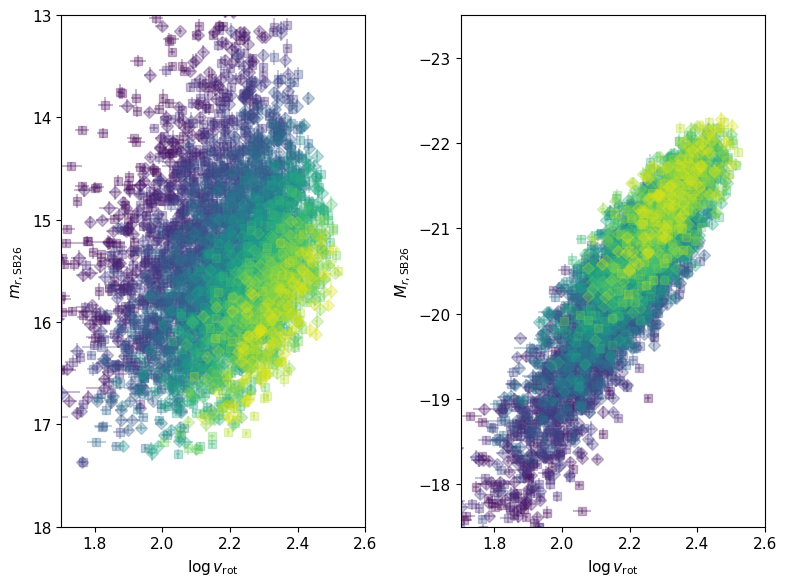

In [56]:
fig, axes = plt.subplots(1,2, figsize=(8,6), sharex=True, tight_layout=True)

# logV0 = 0

_zbin_ids = np.sort(np.unique(zbin_idx))
n_zbins = len(_zbin_ids)

markers = 'sDv^<>'

colors = iter(plt.cm.viridis(np.linspace(0,1, n_zbins + 1)))

for j, _zbin_id in enumerate(_zbin_ids):
    select_zbin = np.isin(zbin_idx, _zbin_id)

    logv = mock_downsample['LOGVROT_MOCK'][select_zbin] #- logV0
    logv_err = 0.434*mock_downsample['LOGVROT_ERR_MOCK'][select_zbin] / mock_downsample['LOGVROT_MOCK'][select_zbin]

    mr26 = mock_downsample['R_MAG_SB26_CORR'][select_zbin]
    mr26_err = mock_downsample['R_MAG_SB26_ERR_CORR'][select_zbin]

    Mr26 = mock_downsample['R_ABSMAG_SB26_MOCK'][select_zbin]
    Mr26_err = mock_downsample['R_ABSMAG_SB26_ERR_MOCK'][select_zbin]

    c = next(colors)

    ax = axes[0]
    ax.errorbar(x=logv, y=mr26, xerr=logv_err, yerr=mr26_err,
                fmt=markers[j % 2], markersize=6, alpha=0.3,
                color=c)

    ax = axes[1]
    ax.errorbar(x=logv, y=Mr26, xerr=logv_err, yerr=Mr26_err,
                fmt=markers[j % 2], markersize=6, alpha=0.3,
                color=c)

ax = axes[0]
ax.set(xlim=(1.7, 2.6),
       ylim=(18, 13),
       xlabel=r'$\log{v_\mathrm{rot}}$',
       ylabel=r'$m_{r,\mathrm{SB26}}$')

ax = axes[1]
ax.set(ylim=(-17.5, -23.5),
       xlabel=r'$\log{v_\mathrm{rot}}$',
       ylabel=r'$M_{r,\mathrm{SB26}}$');

#### Pack the Data and Fit with `MultiLinFit`

In [57]:
bounds = [[-20, 0]]              # Bounds on a (slope)
bounds += n_zbins*[(-20, 20)]    # Bounds on b (intercepts: z-bins)
bounds += [(0,5)]                # Bounds on sigma

# logV0_mock = np.median(mock_downsample['LOGVROT_MOCK'])
# print(logV0_mock)
print(logV0)

datasets = [] # list of (2xN) arrays of the data
covs = []     # covariance of zero point and slope for each "cluster"

for j, _zbin_id in enumerate(_zbin_ids):
    select_zbin = np.isin(zbin_idx, _zbin_id)

    logv = mock_downsample['LOGVROT_MOCK'].to_numpy()[select_zbin] - logV0
    dlogv = mock_downsample['LOGVROT_ERR_MOCK'].to_numpy()[select_zbin]
    mr = mock_downsample['R_MAG_SB26_CORR'].to_numpy()[select_zbin]
    dmr = mock_downsample['R_MAG_SB26_ERR_CORR'].to_numpy()[select_zbin]

    N = len(logv)
    cov = np.empty((2, 2, N))
    for i in range(N):
        cov[:,:,i] = np.array([[dlogv[i]**2, 0.], [0., dmr[i]**2]])
    covs.append(cov)

    data = np.empty((2, N))
    data[0] = logv
    data[1] = mr
    datasets.append(data)

hf = MultiLinFit(datasets, covs, scatter=1)
pars, parscatter, lnpost = hf.optimize(bounds)

2.163980618632272


In [58]:
pars, parscatter

(array([-7.0776541 , 12.87372829, 13.54970902, 14.11881032, 14.48287607,
        14.89419346, 15.21086737, 15.48040728, 15.6890828 , 15.90709234,
        16.04887647, 16.27764196, 16.47437756, 16.60071206, 16.79050236,
        16.97151482, 16.98966632, 17.20863059, 17.23472279]),
 array([0.41037114]))

#### Try the Fit using MCMC

In [59]:
## Use logV0 from data so we can directly compare the zero points
# Pack the calibration set into lists
logv, dlogv = [], []
mr, dmr = [], []
weights = []

# Loop over redshift bins
for j, _zbin_id in enumerate(_zbin_ids):
    select_zbin = np.isin(zbin_idx, _zbin_id)

    logv.append(mock_downsample['LOGVROT_MOCK'].to_numpy()[select_zbin] - logV0)
    dlogv.append(mock_downsample['LOGVROT_ERR_MOCK'].to_numpy()[select_zbin])
    mr.append(mock_downsample['R_MAG_SB26_CORR'].to_numpy()[select_zbin])
    dmr.append(mock_downsample['R_MAG_SB26_ERR_CORR'].to_numpy()[select_zbin])
    weights.append(np.ones_like(mock_downsample['LOGVROT_MOCK'][select_zbin]))

In [60]:
# Number of redshift bins
bounds = [[-20, 0]]        # Bounds on a (slope)
bounds += n_zbins*[(-20, 20)]    # Bounds on b (intercepts: z-bins)
bounds += [(0,5)]          # Bounds on sigma

# logging.warning('Fit does not account for volume weights.')

results = hyperfit_line_multi(logv, mr, dlogv, dmr, bounds, weights=weights, scatter=1)

a_mcmc, b_mcmc, sigma_mcmc, cov_mcmc, mcmc_samples, hf = results

     fun: -2438042.7075383114
     jac: array([  1.39698387, -14.38893259,   8.33533635, -11.08273772,
         0.1862645 ,  -2.37487237,   1.21071925,  -3.35276099,
        -2.98023199,   0.        ,  -0.41909512,  -1.72294662,
        -0.23283062,  -3.21306262,  -0.372529  ,   0.13969837,
       -10.98960547,  13.87670521,  -1.62981437,  -9.49949027])
 message: 'Optimization terminated successfully.'
    nfev: 75615
     nit: 250
 success: True
       x: array([-7.07722687, 12.87371879, 13.5498399 , 14.11880895, 14.48293202,
       14.89420149, 15.21084907, 15.48038976, 15.68905998, 15.90706118,
       16.04883354, 16.27760306, 16.4743042 , 16.60066172, 16.790453  ,
       16.97146445, 16.9892536 , 17.20868875, 17.23437631,  0.41022329])
Ndim: 20 18


100%|██████████| 1000/1000 [01:22<00:00, 12.09it/s]


Niterations/Max Iterations:  1000 / 100000
Integrated ACT/Min Convergence Iterations:  [88.13404785 76.97925939 73.85261994 58.51586424 61.08600763 66.2422174
 51.62250988 42.31017076 43.58595834 72.35213626 46.02735574 49.70238479
 51.56993572 57.16798416 71.73006585 92.03078498 62.74905473 70.23620181
 86.34347003 79.37763421] / 4601.539248862215


100%|██████████| 1000/1000 [01:23<00:00, 12.05it/s]


Niterations/Max Iterations:  2000 / 100000
Integrated ACT/Min Convergence Iterations:  [107.71315682  93.95630648  86.15899168  72.49946149  63.71094531
  58.72305952  53.65196163  62.12100257  61.76221812  61.62148919
  61.77496577  56.98016999  67.18529689  74.57215223  68.04131189
  88.92388096  86.12488476  91.11060293  97.41584402 120.27760493] / 6013.880246628848


100%|██████████| 1000/1000 [01:24<00:00, 11.90it/s]


... (33 outputs left out)

100%|██████████| 1000/1000 [01:21<00:00, 12.27it/s]


Niterations/Max Iterations:  20000 / 100000
Integrated ACT/Min Convergence Iterations:  [186.38469321 155.2749202  127.67269703 109.08082789  92.15273031
  82.65742262  61.97348254  71.75209191  80.72814395  57.84248536
  74.37504358  74.44625034  79.49585593  75.5993269   89.55720637
 105.95877576 107.70466297 150.83126502 138.75564908 199.91488978] / 9995.744489155497


100%|██████████| 1000/1000 [01:21<00:00, 12.28it/s]


Niterations/Max Iterations:  21000 / 100000
Integrated ACT/Min Convergence Iterations:  [186.30886668 162.11563459 130.11818236 104.24937664  93.23146427
  80.03628685  59.59078613  72.63316622  78.00379124  58.59049875
  73.01915385  72.78683144  78.71472975  74.35829804  87.41134202
 104.32266097 106.68169656 147.40952774 139.65651634 205.59228664] / 10279.61433182507


#### Plot the HyperFit Results

In [61]:
m = len(logv)
values = np.median(mcmc_samples, axis=1)
sigmas = np.sqrt(np.diag(cov_mcmc))

multiple = 3.5

limits = []

for i in range(len(values)):
    limits.append([values[i] - multiple*sigmas[i], 
                   values[i] + multiple*sigmas[i]])

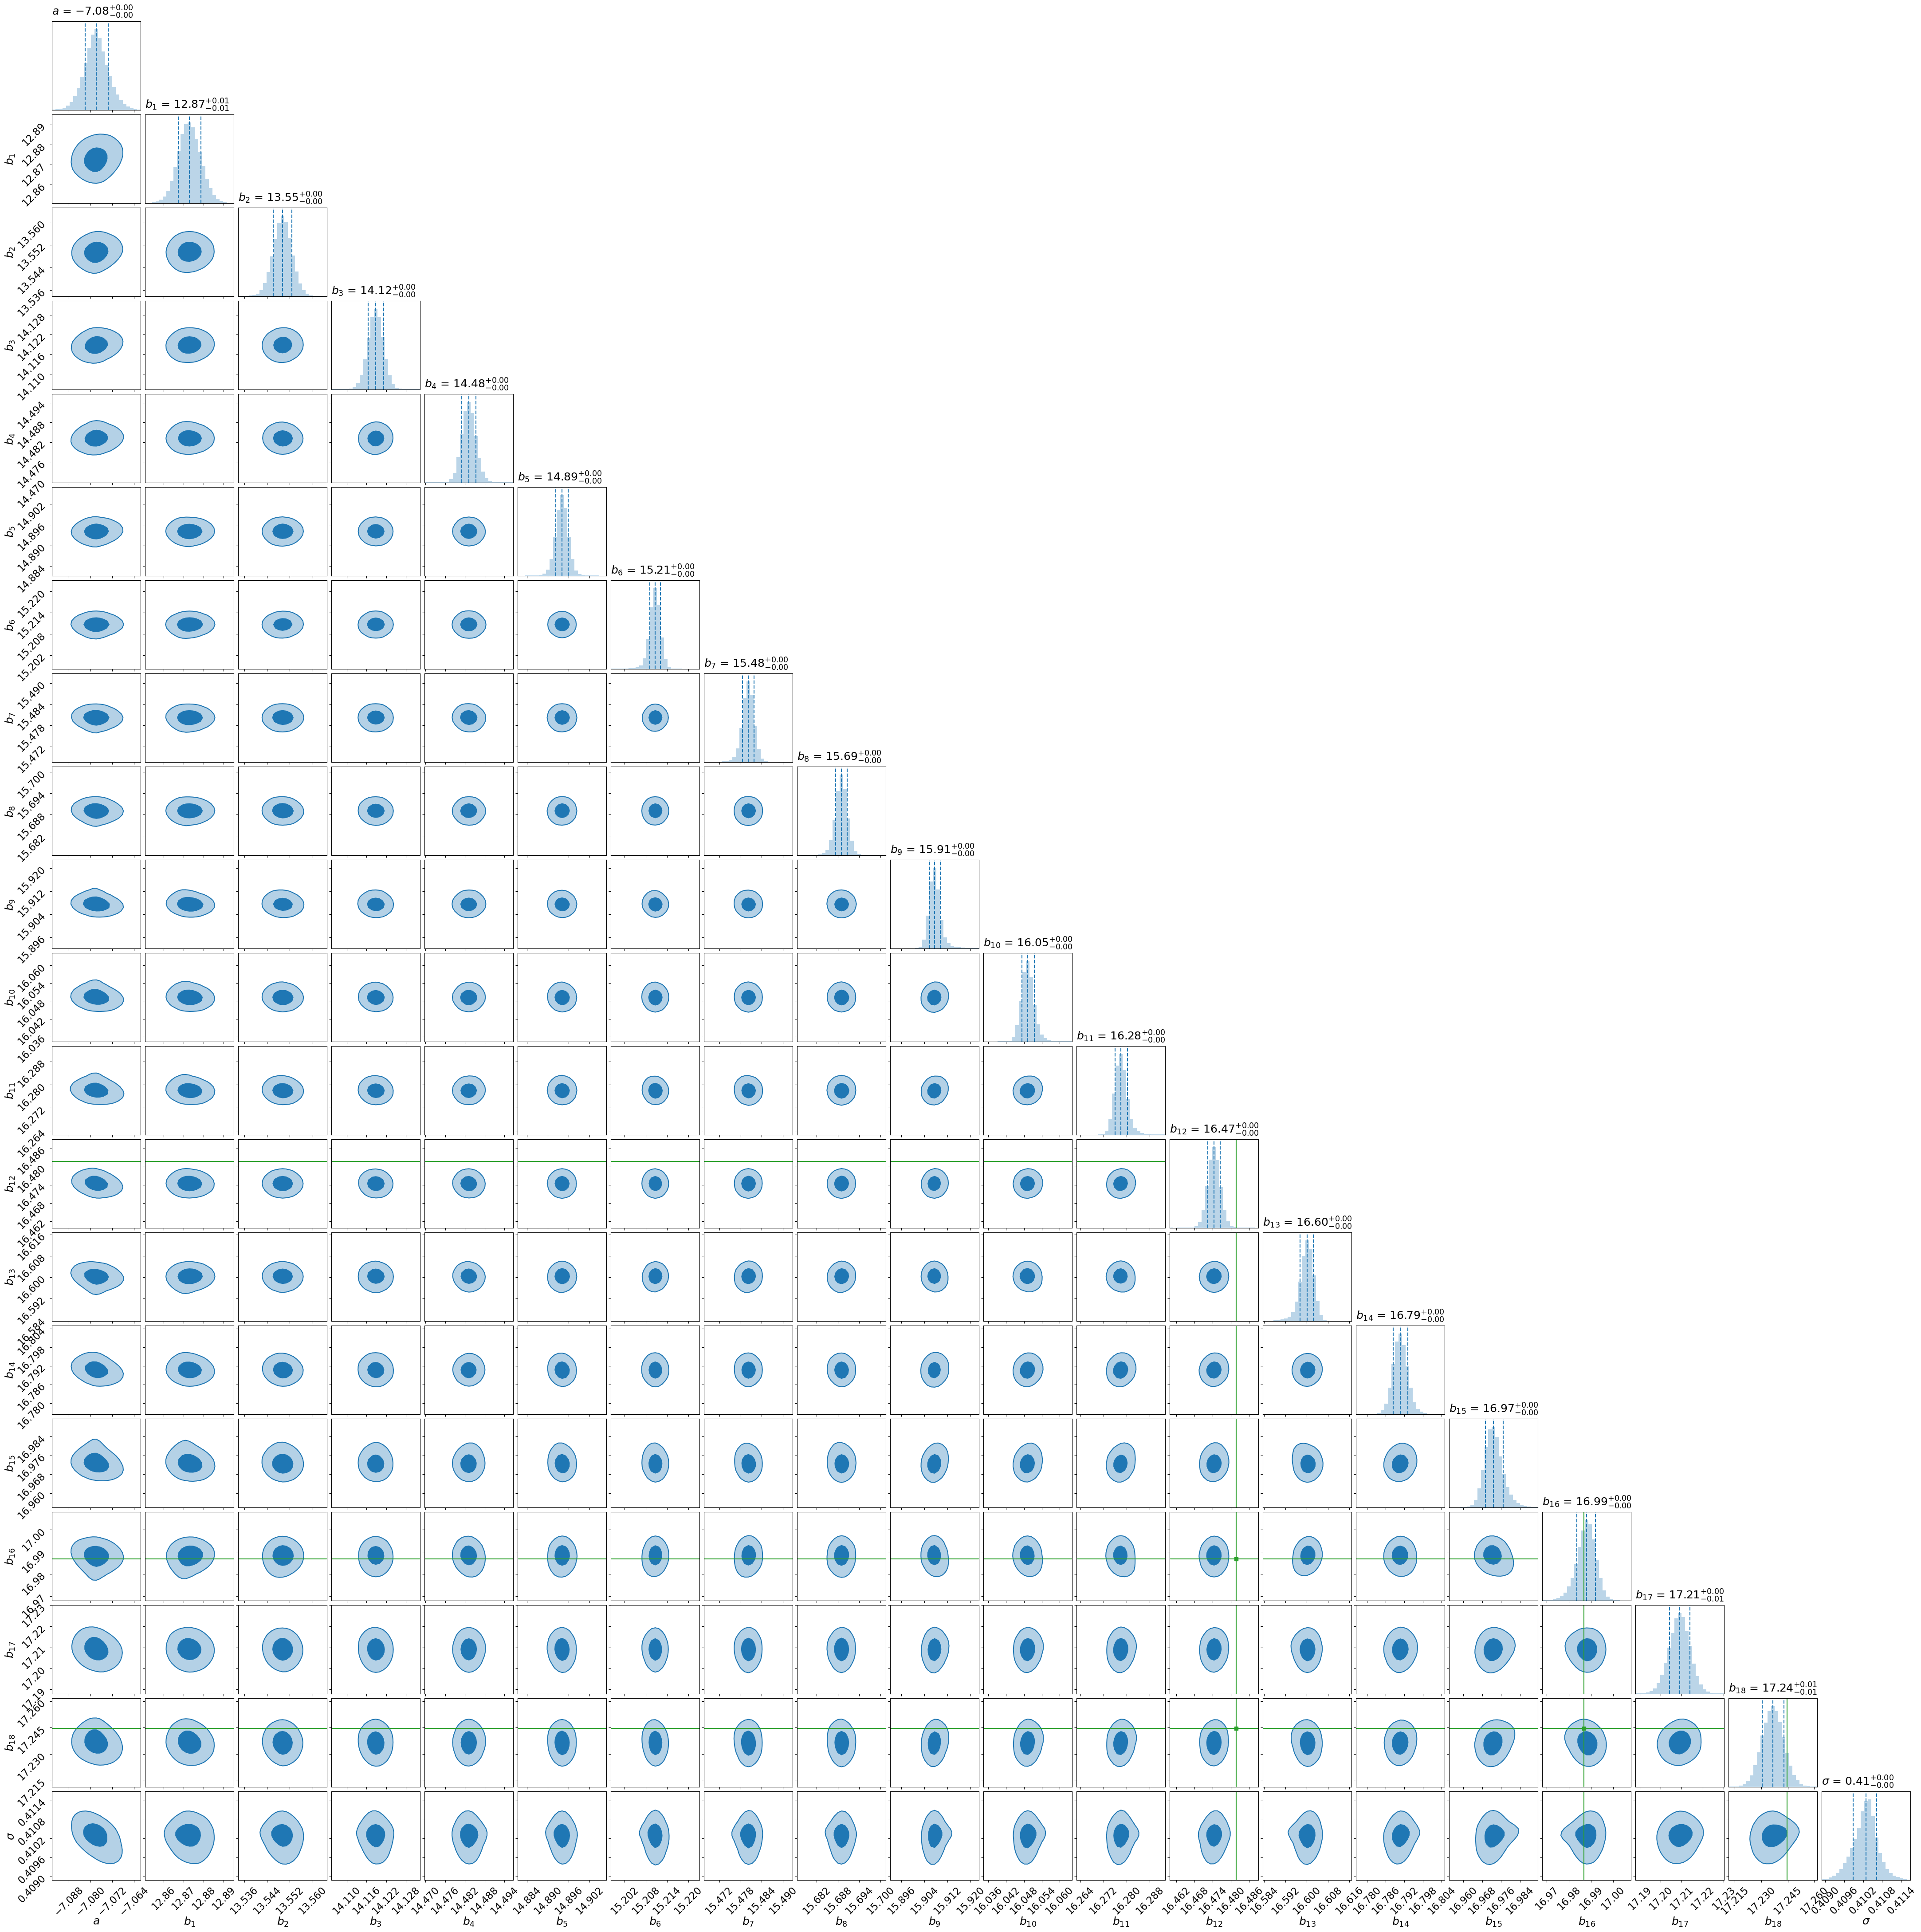

In [62]:
labels  = ['$a$']
labels += [f'$b_{{ {k+1} }}$' for k in np.arange(m)]
labels += [r'$\sigma$']

fig = corner(mcmc_samples.T, bins=25, smooth=1,
             range=limits,
             labels=labels,
             label_kwargs={'fontsize':18},
             labelpad=0.1,
             levels=(1-np.exp(-0.5), 1-np.exp(-2)),
             quantiles=[0.16, 0.5, 0.84],
             color='tab:blue',
             hist_kwargs={'histtype':'stepfilled', 'alpha':0.3},
             plot_datapoints=False,
             fill_contours=True,
             truths=tf_par,
             truth_color='tab:green',
             show_titles=True,
             title_kwargs={"fontsize": 18, 'loc':'left', 'pad':10});

for ax in fig.get_axes():
    ax.tick_params(axis='both', which='major', labelsize=16);

# fig.savefig('tfr_mock_calibration_mcmc.png', dpi=150)

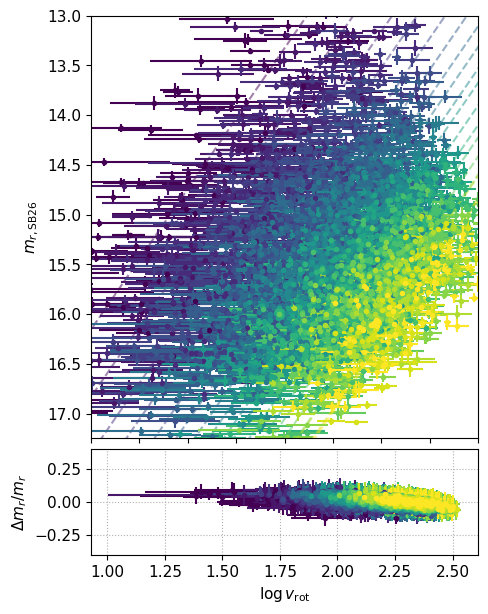

In [63]:
fig, axes = plt.subplots(2, 1, figsize=(5,7),
                         gridspec_kw={'height_ratios':[4,1], 'hspace':0.04, 'wspace':0.25})

_logv = np.arange(0, 3, 0.1) - logV0

color = iter(plt.cm.viridis(np.linspace(0,1, n_zbins)))

for k in range(n_zbins):
    ax = axes[0]
    c = next(color)
    
    eb = ax.errorbar(x=logv[k] + logV0, y=mr[k],
                     xerr=dlogv[k], yerr=dmr[k],
                     fmt='.', color=c,
                     label=f'{zbins[k]:.3f}-{zbins[k+1]:.3f}')

    ax.plot(_logv + logV0, a_mcmc*_logv + b_mcmc[k], color=eb[0].get_color(), ls='--', alpha=0.5)

    ax = axes[1]
    logv_obs = logv[k]
    m_obs = mr[k]
    m_exp = a_mcmc*logv_obs + b_mcmc[k]
    eb = ax.errorbar(x=logv_obs + logV0, y=(m_exp - m_obs)/m_exp,
                     xerr=dlogv[k], yerr=dmr[k],
                     fmt='.', color=c)

ax = axes[0]
ax.set(xlim=[1.7, 2.5],
       ylim=[17.25, 13],
       xticklabels=[],
       ylabel=r'$m_{r,\mathrm{SB26}}$')

ax = axes[1]
ax.grid(ls=':')

ax.set(xlabel=r'$\log{v_\mathrm{rot}}$',
       ylabel=r'$\Delta m_r/m_r$',
       ylim=(-0.4,0.4));

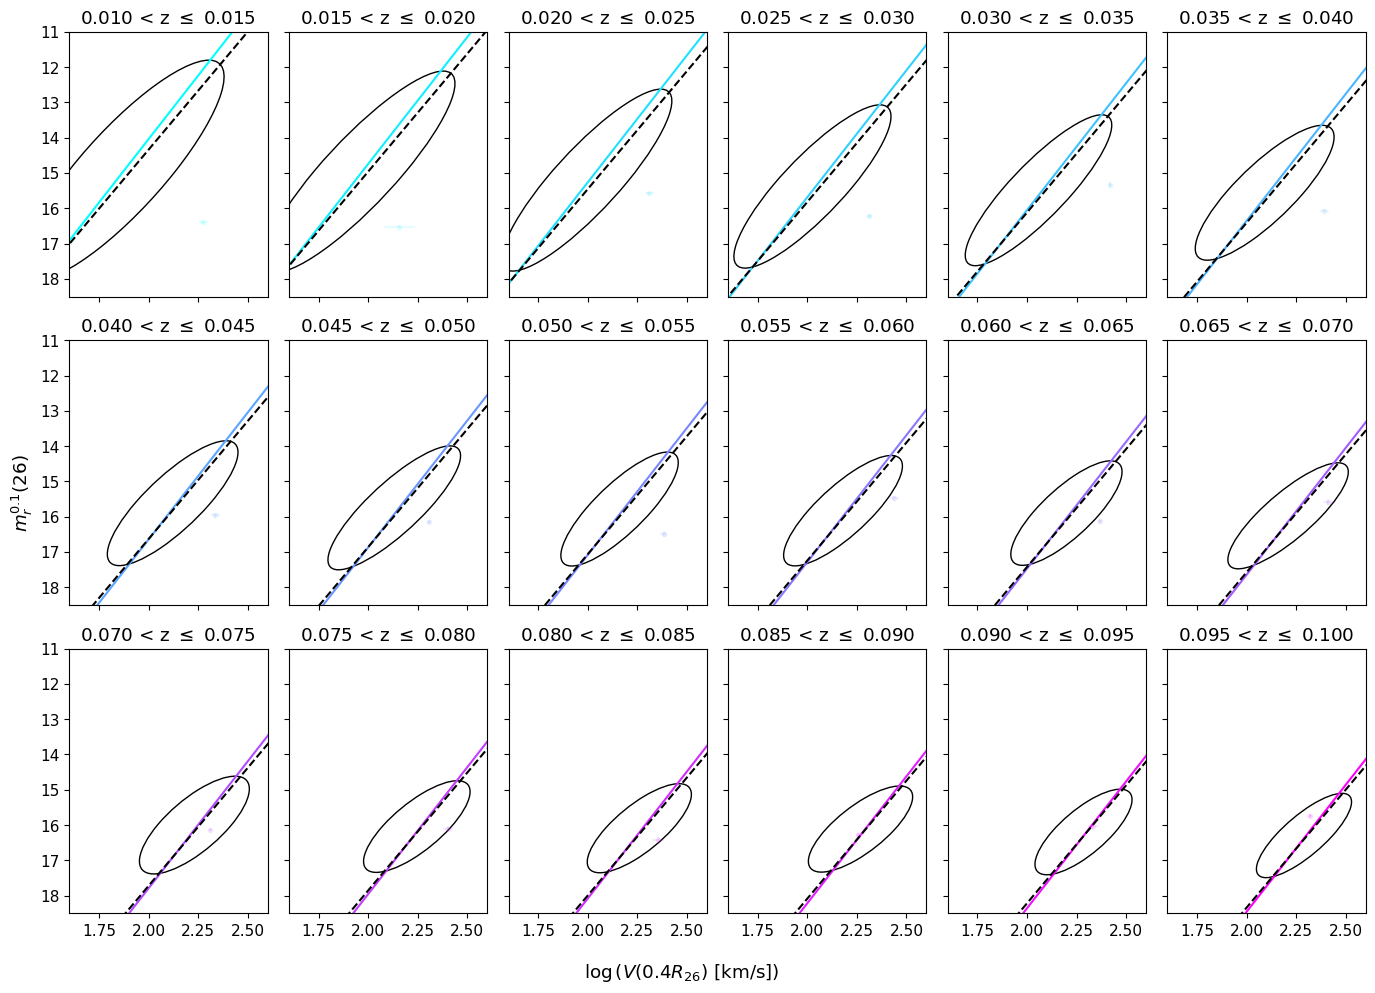

In [132]:
fig, axes = plt.subplots(nrows=3, ncols=6, sharex=True, sharey=True, figsize=(14,10), tight_layout=True)

color = iter(plt.cm.cool(np.linspace(0,1, n_zbins)))
for i in range(n_zbins):
    c = next(color)
    
    row = int(i/6)
    col = i%6
    
    eb = axes[row,col].errorbar(logv[i] + logV0, mr[i], xerr=dlogv[i], yerr=dmr[i], fmt='.', color=c, alpha=0.1)
    axes[row,col].plot(_logv + logV0, a_mcmc*_logv + b_mcmc[i], color=c)
    axes[row,col].plot(_logv + logV0, a*_logv + b[i], 'k--', zorder=20)
    plot_ellipse(mean = [ellipse_params[i+1][0], ellipse_params[i+1][1]],cov = [[ellipse_params[i+1][2], ellipse_params[i+1][3]],[ellipse_params[i+1][4],ellipse_params[i+1][5]]],
                 n_std = ellipse_sigma, ax=axes[row,col], edgecolor='k', facecolor='none')
    
    axes[row,col].set(xlim=[1.6, 2.6], ylim=[18.5, 11], title=f'{zbins[i]:.3f} < z $\leq$ {zbins[i+1]:.3f}')


# Delete extra axes
# fig.delaxes(axs[-1,-1])

fig.supxlabel(r'$\log{(V(0.4R_{26})~[\mathrm{km/s}]}$)')
fig.supylabel(r'$m_r^{0.1} (26)$');

#### Quick Check of Many Realizations of the "Calibration" Sample

In [65]:
bounds = [[-20, 0]]              # Bounds on a (slope)
bounds += n_zbins*[(-20, 20)]    # Bounds on b (intercepts: z-bins)
bounds += [(0,5)]                # Bounds on sigma

a_real, b_real, sigma_real = [], [], []

for i in tqdm(np.arange(25)):
    mock_downsample = downsample(mock, Ntfr)
    
    idx_mock_downsample_good = mag_ellipse_boolean(mock_downsample['zobs'], mock_downsample['LOGVROT_MOCK'], mock_downsample['R_MAG_SB26_CORR'],
                                    ellipse_params, n_std=ellipse_sigma, absmag_cat=mock_downsample['R_ABSMAG_SB26_MOCK'])

    zbin_idx = np.digitize(mock_downsample['zobs'], zbins, right=True)
    no_use = (zbin_idx == 0) | (zbin_idx == len(zbins))
    mock_downsample = downsample(mock_downsample[idx_mock_downsample_good & ~no_use], size=4200)
    
    zbin_idx = np.digitize(mock_downsample['zobs'], zbins, right=True)

    datasets = [] # list of (2xN) arrays of the data
    covs = []     # covariance of zero point and slope for each "cluster"
    
    for j, _zbin_id in enumerate(_zbin_ids):
        select_zbin = np.isin(zbin_idx, _zbin_id)
    
        logv = mock_downsample['LOGVROT_MOCK'].to_numpy()[select_zbin] - logV0
        dlogv = mock_downsample['LOGVROT_ERR_MOCK'].to_numpy()[select_zbin]
        mr = mock_downsample['R_MAG_SB26_CORR'].to_numpy()[select_zbin]
        dmr = mock_downsample['R_MAG_SB26_ERR_CORR'].to_numpy()[select_zbin]
    
        N = len(logv)
        cov = np.empty((2, 2, N))
        for k in range(N):
            cov[:,:,k] = np.array([[dlogv[k]**2, 0.], [0., dmr[k]**2]])
        covs.append(cov)
    
        data = np.empty((2, N))
        data[0] = logv
        data[1] = mr
        datasets.append(data)
    
    hf = MultiLinFit(datasets, covs, scatter=1)
    pars, parscatter, lnpost = hf.optimize(bounds)

    a_real.append(pars[0])
    b_real.append(pars[1:])
    sigma_real.append(parscatter[0])

100%|██████████| 25/25 [34:13<00:00, 82.15s/it]


[Text(0.5, 1.0, '$\\hat{\\sigma}=0.41\\pm0.01$'),
 Text(0.5, 0, 'magnitude scatter $\\sigma$')]

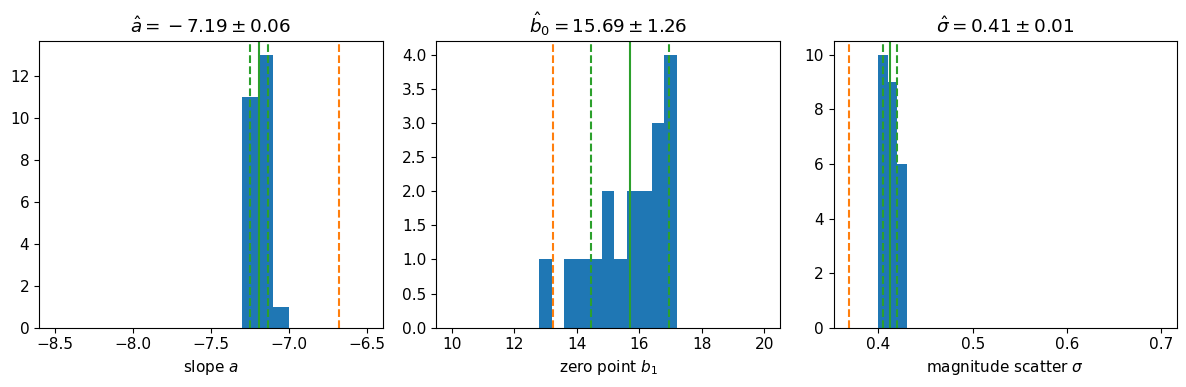

In [66]:
fig, axes = plt.subplots(1,3, figsize=(12,4), tight_layout=True)

ax = axes[0]
ax.hist(a_real, bins=np.arange(-8.5,-6.4,0.1))
ax.axvline(tf_par[0], color='tab:orange', ls='--')
ax.axvline(np.mean(a_real), color='tab:green')
ax.axvline(np.mean(a_real) - np.std(a_real), color='tab:green', ls='--')
ax.axvline(np.mean(a_real) + np.std(a_real), color='tab:green', ls='--')
ax.set(title=rf'$\hat{{a}}={np.mean(a_real):.2f}\pm{np.std(a_real):.2f}$',
       xlabel=r'slope $a$')

ax = axes[1]
ax.hist(b_real[0], bins=np.arange(10,20.4,0.4))
ax.axvline(tf_par[1], color='tab:orange', ls='--')
ax.axvline(np.mean(b_real[0]), color='tab:green')
ax.axvline(np.mean(b_real[0]) - np.std(b_real[0]), color='tab:green', ls='--')
ax.axvline(np.mean(b_real[0]) + np.std(b_real[0]), color='tab:green', ls='--')
ax.set(title=rf'$\hat{{b}}_0={np.mean(b_real[0]):.2f}\pm{np.std(b_real):.2f}$',
       xlabel=r'zero point $b_1$')

ax = axes[2]
ax.hist(sigma_real, bins=np.arange(0.4,0.71,0.01))
ax.axvline(tf_par[-1], color='tab:orange', ls='--')
ax.axvline(np.mean(sigma_real), color='tab:green')
ax.axvline(np.mean(sigma_real) - np.std(sigma_real), color='tab:green', ls='--')
ax.axvline(np.mean(sigma_real) + np.std(sigma_real), color='tab:green', ls='--')
ax.set(title=rf'$\hat{{\sigma}}={np.mean(sigma_real):.2f}\pm{np.std(sigma_real):.2f}$',
       xlabel=r'magnitude scatter $\sigma$')

# fig.set_facecolor('none')
# fig.savefig(f'tfr_fit_param_spread_equal_weight_{os.path.basename(mockfile)[:-9]}.png', dpi=150)
# # fig.savefig('tfr_fit_param_spread_error_weighted.png', dpi=150)
# # fig.savefig('tfr_fit_param_spread_var_weighted.png', dpi=150)

In [67]:
a_avg = np.average(a_real)
b_avg = np.average(b_real, axis=0)
sigma_avg = np.average(sigma_real)
a_avg, b_avg, sigma_avg

(-7.191515964891369,
 array([12.85896048, 13.56349498, 14.08328153, 14.50448595, 14.87304277,
        15.17760827, 15.46522653, 15.691695  , 15.90330148, 16.10417031,
        16.29505551, 16.46744012, 16.61120683, 16.77539307, 16.90035897,
        17.03378644, 17.18016557, 17.27924479]),
 0.4119757378883902)

In [68]:
a_mcmc, b_mcmc, sigma_mcmc = a_avg, b_avg, sigma_avg

#### Apply Velocity and Dwarf Identification to the Full Sample

In [69]:
idx_mock_good = mag_ellipse_boolean(mock['zobs'], mock['LOGVROT_MOCK'], mock['R_MAG_SB26_CORR'],
                                    ellipse_params, n_std=ellipse_sigma, absmag_cat=mock['R_ABSMAG_SB26_MOCK'])

mock['DWARF'] = np.zeros_like(mock['LOGVROT_MOCK'], dtype=bool)
mock.loc[~idx_mock_good, 'DWARF'] = True

mock['MAIN'] = np.zeros_like(mock['DWARF'], dtype=bool)
mock.loc[idx_mock_good, 'MAIN'] = True

In [74]:
# mock_main = mock['MAIN']
# mock_dwarfs = mock['DWARF']

In [70]:
len(mock), np.sum(mock['MAIN']) 

(203127, 170580)

In [71]:
# Identify zbins for all mock galaxies
zbin_idx = np.digitize(mock['zobs'], zbins, right=True)

### Compute TFR Distance Modulus

Using the "measured" apparent magnitude and the TFR-predicted absolute magnitude from the "calibration" above, compute the distance modulus:

$$
\mu_\mathrm{TF} =  m_{r,\mathrm{SB_{26}}} - M_{r,\mathrm{TF}}.
$$

Also compute the log distance ratio

$$
\eta = \log{\left(\frac{D_z}{D_\mathrm{TFR}}\right)}
$$

In [116]:
#- Compute TF absolute magnitude and uncertainties using the MCMC from HyperFit.
#  Downsample the MCMC significantly for this quick calculation.

# Redshift bin centers:
zc = 0.5*dz + zbins[:-1]
mu_zc = cosmology.distmod(zc)

# Convert each redshift bin zero point to an abs mag
B_mcmc = b_mcmc - mu_zc.value

# Compute indices for intercepts.
# For galaxies outside the calibration range, assign them to the closest bin.
B_idx = zbin_idx - 1
B_idx[zbin_idx == 0] = 0
B_idx[zbin_idx == len(zbins)] = len(zbins) - 2

# Use the calibrated TFR to compute abs mag.
logV0_mock = np.median(mock['LOGVROT_MOCK'])
Mr_TF = a_mcmc * (mock['LOGVROT_MOCK'] - logV0) + B_mcmc[B_idx]

# Compute the uncertainty in TFR abs mag.
Mr_TF_err = np.zeros_like(Mr_TF)

for i in tqdm(range(len(mock))):
    logv_random = np.random.normal(mock['LOGVROT_MOCK'].iloc[i], 0.434*mock['LOGVROT_ERR_MOCK'].iloc[i], size=1000)
    Mr_stat = a_mcmc*(logv_random - logV0) + B_mcmc[B_idx[i]]
    Mr_TF_err[i] = np.sqrt(np.nanstd(Mr_stat)**2 + sigma_mcmc**2)

# Mr_TF = a_mcmc * (logvrot_mock - logV0_mock) + b_mcmc
# a_sampled, b_sampled = mcmc_samples[0][::500], mcmc_samples[1][::500]
# Mr_TF_err = np.std(a_sampled * (logvrot_mock[:, np.newaxis] - logV0_mock) + b_sampled, axis=1)

mu_TF = mock['R_MAG_SB26_CORR'] - Mr_TF
mu_TF_err = np.sqrt(mock['R_ABSMAG_SB26_ERR_MOCK']**2 + Mr_TF_err**2)

mu_zcmb = cosmology.distmod(mock['zobs']).to_value('mag')
mu_zcos = cosmology.distmod(mock['zcos']).to_value('mag')

eta_true = 0.2 * (mu_zcmb - mu_zcos)
eta_mock = 0.2 * (mu_zcmb - mu_TF)
eta_err_mock = 0.2 * mu_TF_err

100%|██████████| 203127/203127 [00:34<00:00, 5861.30it/s]


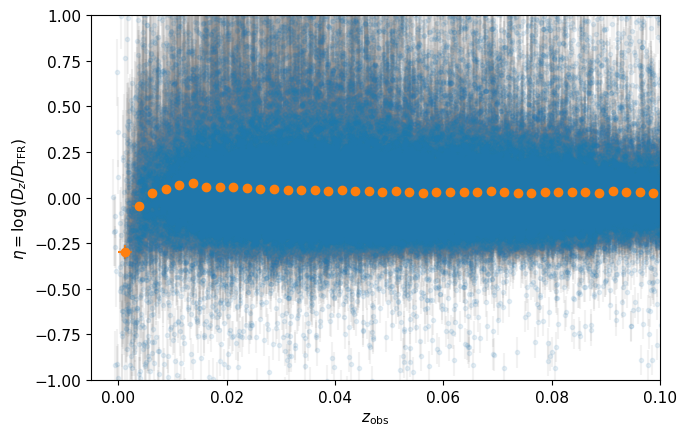

In [101]:
fig, ax = plt.subplots(1,1, figsize=(7,4.5), tight_layout=True)
ax.errorbar(mock['zobs'], eta_mock,
            yerr=eta_err_mock,
            fmt='.',
            alpha=0.1,
            ecolor='gray')

zbins = np.arange(0, 0.1025, 0.0025)
dz = 0.5*np.diff(zbins)
zc = 0.5*(zbins[1:] + zbins[:-1])

_, eta_avg, eta_std = profile_histogram(mock['zobs'], eta_mock, zbins)
ax.errorbar(zc, eta_avg, xerr=dz, yerr=eta_std, fmt='o', color='tab:orange')

ax.set(xlabel=r'$z_\mathrm{obs}$',
       xlim=(-0.005,0.1),
       ylim=(-1,1),
       ylabel=r'$\eta = \log{(D_z / D_\mathrm{TFR})}$');

fig.set_facecolor('none')
# fig.savefig('tfr_mock_eta.png', dpi=150);

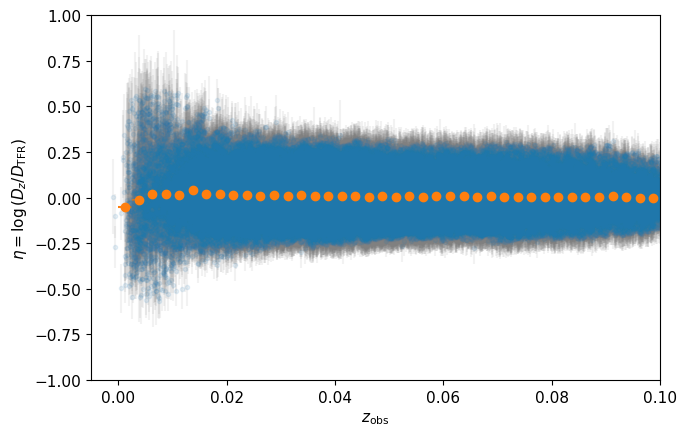

In [102]:
fig, ax = plt.subplots(1,1, figsize=(7,4.5), tight_layout=True)
ax.errorbar(mock['zobs'][idx_mock_good], eta_mock[idx_mock_good],
            yerr=eta_err_mock[idx_mock_good],
            fmt='.',
            alpha=0.1,
            ecolor='gray')

zbins = np.arange(0, 0.1025, 0.0025)
dz = 0.5*np.diff(zbins)
zc = 0.5*(zbins[1:] + zbins[:-1])

_, eta_avg, eta_std = profile_histogram(mock['zobs'][idx_mock_good], eta_mock[idx_mock_good], zbins)
ax.errorbar(zc, eta_avg, xerr=dz, yerr=eta_std, fmt='o', color='tab:orange')

ax.set(xlabel=r'$z_\mathrm{obs}$',
       xlim=(-0.005,0.1),
       ylim=(-1,1),
       ylabel=r'$\eta = \log{(D_z / D_\mathrm{TFR})}$');

fig.set_facecolor('none')

/tmp/ipykernel_1377377/1790439695.py:1: RuntimeWarning: invalid value encountered in log10
  logdist_true = np.log10(cosmology.comoving_distance(mock['zobs'].to_numpy()).value/cosmology.comoving_distance(mock['zcos'].to_numpy()).value)


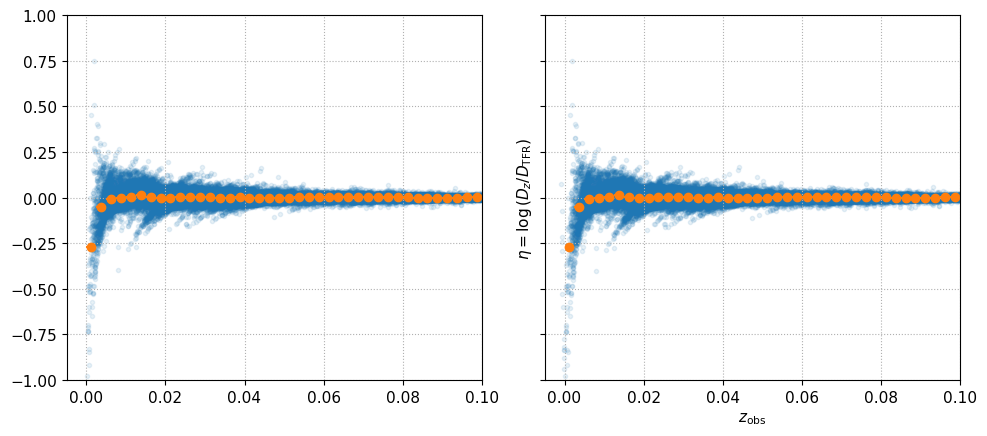

In [103]:
logdist_true = np.log10(cosmology.comoving_distance(mock['zobs'].to_numpy()).value/cosmology.comoving_distance(mock['zcos'].to_numpy()).value)

fig, axes = plt.subplots(1,2, figsize=(10,4.5), tight_layout=True, sharex=True, sharey=True)

ax = axes[0]
ax.scatter(mock['zobs'], logdist_true, marker='.', alpha=0.1)

ax = axes[1]
ax.scatter(mock['zobs'], eta_true, marker='.', alpha=0.1)

zbins = np.arange(0, 0.1025, 0.0025)
dz = 0.5*np.diff(zbins)
zc = 0.5*(zbins[1:] + zbins[:-1])

ax = axes[0]
_, eta_avg, eta_std = profile_histogram(mock['zobs'], logdist_true, zbins)
ax.errorbar(zc, eta_avg, xerr=dz, yerr=eta_std, fmt='o', color='tab:orange')
ax.grid(ls=':')

ax = axes[1]
_, eta_avg, eta_std = profile_histogram(mock['zobs'], eta_true, zbins)
ax.errorbar(zc, eta_avg, xerr=dz, yerr=eta_std, fmt='o', color='tab:orange')

ax.set(xlabel=r'$z_\mathrm{obs}$',
       xlim=(-0.005,0.1),
       ylim=(-1,1),
       ylabel=r'$\eta = \log{(D_z / D_\mathrm{TFR})}$')
ax.grid(ls=':');

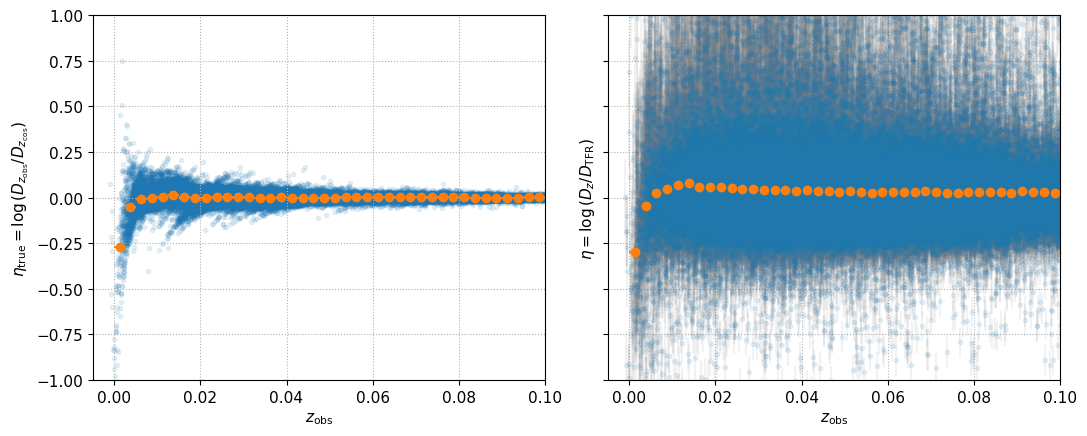

In [104]:
fig, axes = plt.subplots(1,2, figsize=(11,4.5), tight_layout=True, sharex=True, sharey=True)

ax = axes[0]
ax.scatter(mock['zobs'], eta_true, marker='.', alpha=0.1)

ax = axes[1]
ax.errorbar(mock['zobs'], eta_mock, yerr=eta_err_mock, fmt='.', alpha=0.1, ecolor='gray')

zbins = np.arange(0, 0.1025, 0.0025)
dz = 0.5*np.diff(zbins)
zc = 0.5*(zbins[1:] + zbins[:-1])

ax = axes[0]
_, eta_avg, eta_std = profile_histogram(mock['zobs'], eta_true, zbins)
ax.errorbar(zc, eta_avg, xerr=dz, yerr=eta_std, fmt='o', color='tab:orange')
ax.set(xlabel=r'$z_\mathrm{obs}$',
       xlim=(-0.005,0.1),
       ylim=(-1,1),
       ylabel=r'$\eta_\mathrm{true} = \log{(D_{z_\mathrm{obs}} / D_{z_\mathrm{cos}})}$')
ax.grid(ls=':')

ax = axes[1]
_, eta_avg, eta_std = profile_histogram(mock['zobs'], eta_mock, zbins)
ax.errorbar(zc, eta_avg, xerr=dz, yerr=eta_std, fmt='o', color='tab:orange')
ax.set(xlabel=r'$z_\mathrm{obs}$',
       xlim=(-0.005,0.1),
       ylim=(-1,1),
       ylabel=r'$\eta = \log{(D_z / D_\mathrm{TFR})}$')
ax.grid(ls=':');

fig.set_facecolor('none')
# fig.savefig('tfr_mock_eta_true_mock.png', dpi=150);

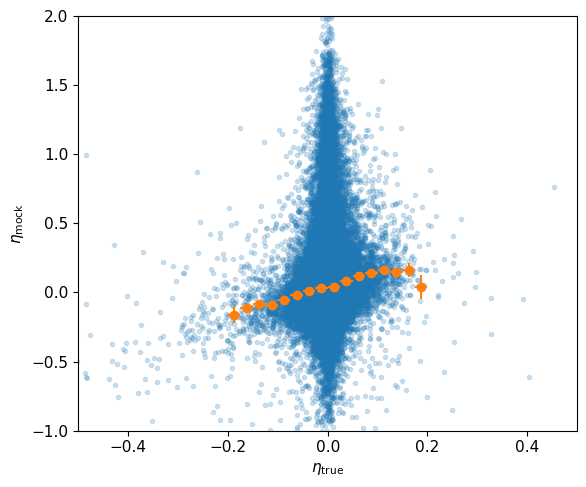

In [105]:
fig, ax = plt.subplots(1,1, figsize=(6,5), tight_layout=True)

ax.scatter(eta_true, eta_mock, alpha=0.2, marker='.')

eta_bins = np.arange(-0.2, 0.225, 0.025)
eta_c = 0.5*(eta_bins[1:] + eta_bins[:-1])
deta = 0.5*np.diff(eta_bins)
_, eta_avg, eta_std = profile_histogram(eta_true, eta_mock, eta_bins)

ax.errorbar(eta_c, eta_avg, xerr=deta, yerr=eta_std, fmt='o', color='tab:orange')

ax.set(xlim=(-0.5,0.5),
       xlabel=r'$\eta_\mathrm{true}$',
       ylim=(-1,2),
       ylabel=r'$\eta_\mathrm{mock}$');

/tmp/ipykernel_1377377/3818747994.py:50: RuntimeWarning: invalid value encountered in true_divide
  e = np.sqrt((mean2 - mean**2) / (N - 1))


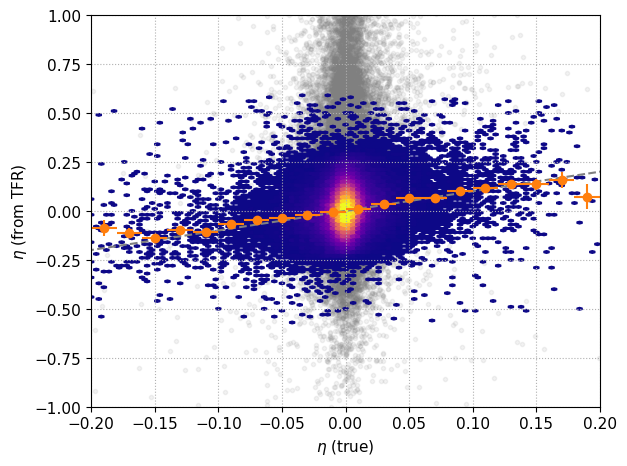

In [112]:
plt.figure(tight_layout=True)

plt.plot(eta_true[~idx_mock_good], eta_mock[~idx_mock_good], '.', c='gray', alpha=0.1, zorder=0)
# plt.plot(eta_true[mock_main], eta_mock[mock_main], '.', alpha=0.1, zorder=1)
plt.hexbin(eta_true[idx_mock_good], 
           eta_mock[idx_mock_good], 
           cmap='plasma', 
           mincnt=1, 
           vmin=1, 
           vmax=1000, 
           gridsize=(100,100), 
           extent=(-0.2, 0.2, -1, 1))

plt.plot([-5, 2], [-5, 2], '--', c='gray')

eta_bins = np.arange(-0.5, 0.3, 0.02)
d_eta = 0.5*np.diff(eta_bins)
eta_c = 0.5*(eta_bins[1:] + eta_bins[:-1])

_, eta_avg, eta_std = profile_histogram(eta_true[idx_mock_good], eta_mock[idx_mock_good], eta_bins, median=True)
plt.errorbar(eta_c, eta_avg, xerr=d_eta, yerr=eta_std, fmt='o', color='tab:orange', zorder=2)

plt.grid(ls=':')

plt.xlim([-0.2, 0.2])
plt.ylim([-1, 1])

plt.xlabel(r'$\eta$ (true)')
plt.ylabel(r'$\eta$ (from TFR)');

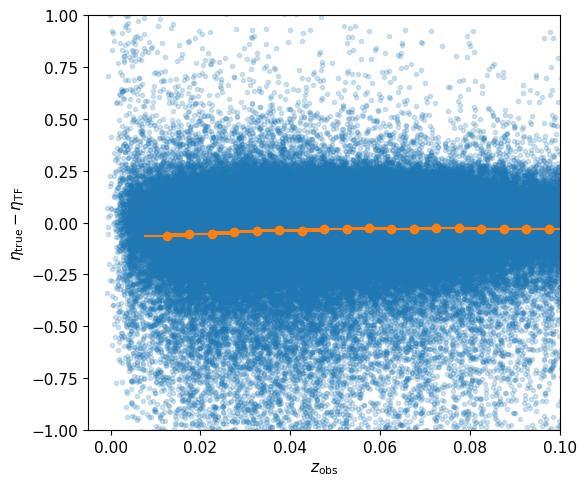

In [117]:
fig, ax = plt.subplots(1,1, figsize=(6,5), tight_layout=True)

ax.scatter(mock['zobs'], eta_true - eta_mock, alpha=0.2, marker='.')

_, deta_avg, deta_std = profile_histogram(mock['zobs'], eta_true - eta_mock, zbins)
ax.errorbar(zc, deta_avg, xerr=dz, yerr=deta_std, fmt='o', color='tab:orange')

ax.set(xlabel=r'$z_\mathrm{obs}$',
       xlim=(-0.005,0.1),
       ylim=(-1,1),
       ylabel=r'$\eta_\mathrm{true} - \eta_\mathrm{TF}$');

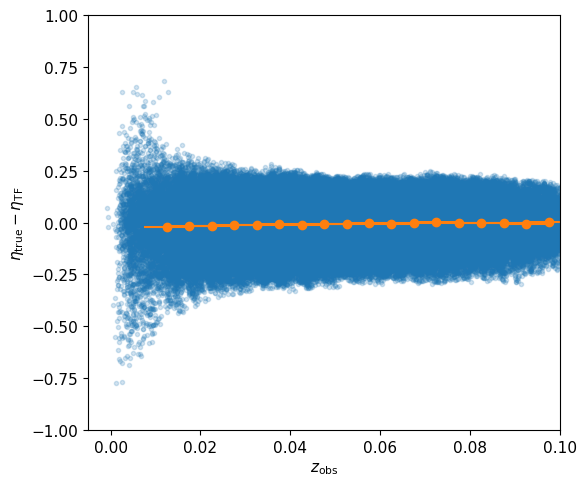

In [118]:
fig, ax = plt.subplots(1,1, figsize=(6,5), tight_layout=True)

ax.scatter(mock['zobs'][idx_mock_good], eta_true[idx_mock_good] - eta_mock[idx_mock_good], alpha=0.2, marker='.')

_, deta_avg, deta_std = profile_histogram(mock['zobs'][idx_mock_good], eta_true[idx_mock_good] - eta_mock[idx_mock_good], zbins)
ax.errorbar(zc, deta_avg, xerr=dz, yerr=deta_std, fmt='o', color='tab:orange')

ax.set(xlabel=r'$z_\mathrm{obs}$',
       xlim=(-0.005,0.1),
       ylim=(-1,1),
       ylabel=r'$\eta_\mathrm{true} - \eta_\mathrm{TF}$');

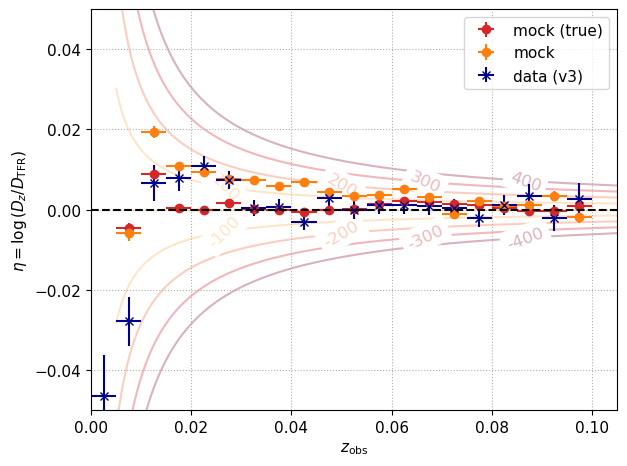

In [120]:
fig = plt.figure(tight_layout=True)

_zbins = np.arange(0, 0.105, 0.005)
dz = 0.5*np.diff(_zbins)
zc = 0.5*(_zbins[1:] + _zbins[:-1])


plt.grid(ls=':')

# True mock
_, eta_avg, eta_std = profile_histogram(mock['zobs'][mock['MAIN']], 
                                        eta_true[mock['MAIN']], 
                                        _zbins)
plt.errorbar(zc, eta_avg, xerr=dz, yerr=eta_std, fmt='o', color='tab:red', label='mock (true)')

# Mock
_, eta_avg, eta_std = profile_histogram(mock['zobs'][mock['MAIN']], 
                                        eta_mock[mock['MAIN']], 
                                        _zbins, 
                                        weights=eta_err_mock[mock['MAIN']]**-2, 
                                        weighted=True)
plt.errorbar(zc, eta_avg, xerr=dz, yerr=eta_std, fmt='o', color='tab:orange', label='mock')

# Data
_, data_eta_avg, data_eta_std = profile_histogram(tfrcat['Z_DESI'][tfrcat['MAIN']], 
                                                  tfrcat['LOGDIST'][tfrcat['MAIN']], 
                                                  _zbins, 
                                                  weights=tfrcat['LOGDIST_ERR'][tfrcat['MAIN']]**-2, 
                                                  weighted=True)
plt.errorbar(zc, data_eta_avg, xerr=dz, yerr=data_eta_std, fmt='x', color='darkblue', label=f'data ({tfr_version})')

#-------------------------------------------------------------------------------
# PV lines (code taken from Cullen)
#-------------------------------------------------------------------------------
LightSpeed = const.c.to('km/s').value
velarray = np.arange(-400, 401, 100)
zarray = np.linspace(0.005, 0.11, 200)

dzarray = cosmology.comoving_distance(zarray).value
dharray = cosmology.comoving_distance(np.outer(1.0/(1.0 + velarray/LightSpeed), 
    								  (1.0 + zarray)) - 1.0).value
deltamarray = np.log10(dzarray/dharray)

rotation = [20.0, 25.0, 30.0, 45.0, 0.0, -45.0, -30.0, -25.0, -20.0]
labels = ["-400", "-300", "-200", "-100", "0", "100", "200", "300", "400"]
xcoord = np.array([26000.0, 20000.0, 15000.0, 8000.0, -1000.0, 8000.0, 15000.0, 20000.0, 26000.0])
coord = np.searchsorted(zarray, xcoord/LightSpeed)
ycoord = np.array([deltamarray[i,j] for i, j in enumerate(coord)])

colors = 0.8*np.fabs(velarray)/np.amax(np.fabs(velarray)) + 0.2

for v in range(len(velarray)):
    c = plt.cm.YlOrRd(colors[v])

    plt.plot(zarray, deltamarray[v,:], 
             color=c, 
             linestyle='-', 
             alpha=0.3, 
             zorder=0)

    if (v != 4):
        plt.text(xcoord[v]/LightSpeed, ycoord[v], 
                 labels[v], 
                 color=c, 
                 fontsize=12, 
                 rotation=rotation[v], 
                 ha="center", 
                 va="center", 
                 bbox=dict(boxstyle="square", ec="w", fc="w"), 
                 zorder=1, 
                 alpha=0.3)

# Line at eta = 0
plt.hlines(0, 0, 0.2, linestyles='dashed', colors='k', zorder=5)
#-------------------------------------------------------------------------------

plt.legend()

plt.xlabel(r'$z_\mathrm{obs}$')
plt.ylabel(r'$\eta = \log{(D_z / D_\mathrm{TFR})}$')

plt.xlim(0,0.105)
plt.ylim(-0.05, 0.05);

# fig.savefig('tfr_mock_eta.png', dpi=150);

## Redshift distribution

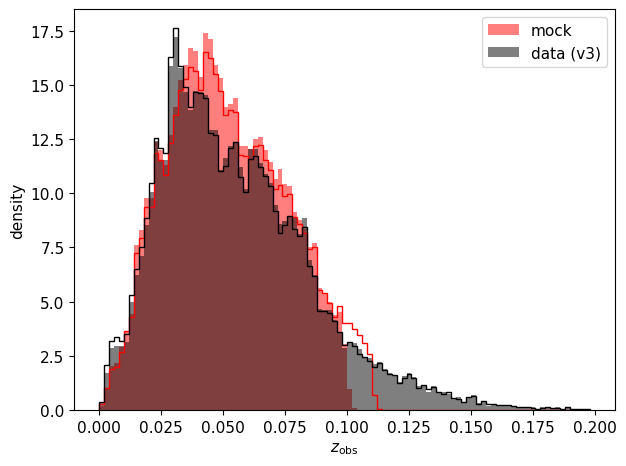

In [122]:
plt.figure(tight_layout=True)

_zbins = np.arange(0, 0.2, 0.002)

# Mocks
plt.hist(mock['zobs'], bins=_zbins, density=True, color='r', histtype='step')
plt.hist(mock['zobs'][mock['MAIN']], bins=_zbins, density=True, color='r', alpha=0.5, label='mock')

# Data
plt.hist(tfrcat['Z_DESI'], bins=_zbins, density=True, color='k', histtype='step')
plt.hist(tfrcat['Z_DESI'][tfrcat['MAIN']], bins=_zbins, density=True, color='k', alpha=0.5, label=f'data ({tfr_version})')

plt.legend()

plt.xlabel(r'$z_\mathrm{obs}$')
plt.ylabel('density');

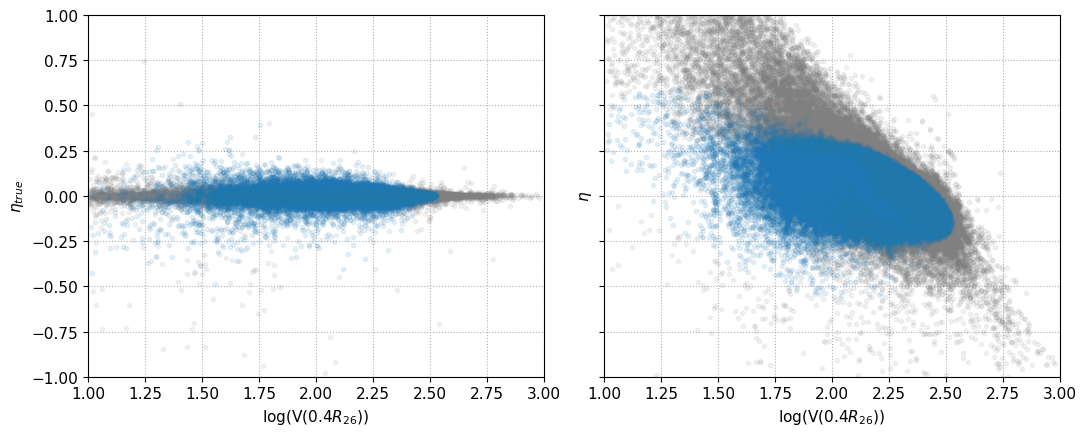

In [123]:
fig, axes = plt.subplots(1,2, figsize=(11,4.5), tight_layout=True, sharex=True, sharey=True)

# Truth
ax = axes[0]
ax.plot(logvrot_mock[~mock['MAIN']], eta_true[~mock['MAIN']], '.', alpha=0.1, c='gray')
ax.plot(logvrot_mock[mock['MAIN']], eta_true[mock['MAIN']], '.', alpha=0.1)

ax.grid(ls=':')

ax.set(xlabel='log(V(0.4$R_{26}$))', 
       ylabel='$\eta_{true}$', 
       ylim=(-1, 1), 
       xlim=(1,3))


# Mock (generated)
ax = axes[1]
ax.plot(logvrot_mock[~mock['MAIN']], eta_mock[~mock['MAIN']], '.', alpha=0.1, c='gray')
ax.plot(logvrot_mock[mock['MAIN']], eta_mock[mock['MAIN']], '.', alpha=0.1)

ax.grid(ls=':')

ax.set(xlabel='log(V(0.4$R_{26}$))', 
       ylabel='$\eta$');

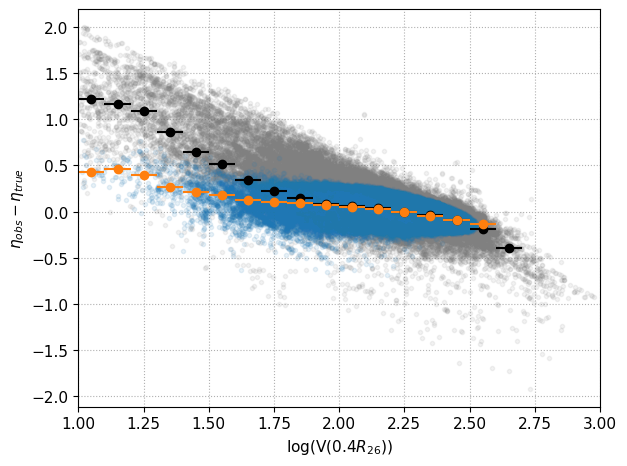

In [125]:
logv_bins = np.arange(1, 2.75, 0.1)
dv = 0.5*np.diff(logv_bins)
vc = 0.5*(logv_bins[1:] + logv_bins[:-1])

plt.figure(tight_layout=True)

plt.plot(logvrot_mock[~mock['MAIN']], 
         eta_mock[~mock['MAIN']] - eta_true[~mock['MAIN']], 
         '.', c='gray', alpha=0.1)

plt.plot(logvrot_mock[mock['MAIN']], 
         eta_mock[mock['MAIN']] - eta_true[mock['MAIN']], 
         '.', c='tab:blue', alpha=0.1)

_, dn_avg, dn_std = profile_histogram(logvrot_mock, eta_mock - eta_true, logv_bins, median=True)
plt.errorbar(vc, dn_avg, xerr=dv, yerr=dn_std, fmt='o', color='black')

_, dn_avg, dn_std = profile_histogram(logvrot_mock[mock['MAIN']], 
                                      eta_mock[mock['MAIN']] - eta_true[mock['MAIN']], 
                                      logv_bins, 
                                      median=True)
plt.errorbar(vc, dn_avg, xerr=dv, yerr=dn_std, fmt='o', color='tab:orange')

plt.grid(ls=':')

plt.xlim((1,3))

plt.xlabel('log(V(0.4$R_{26}$))')
plt.ylabel('$\eta_{obs} - \eta_{true}$');

## Correlation with magnitude

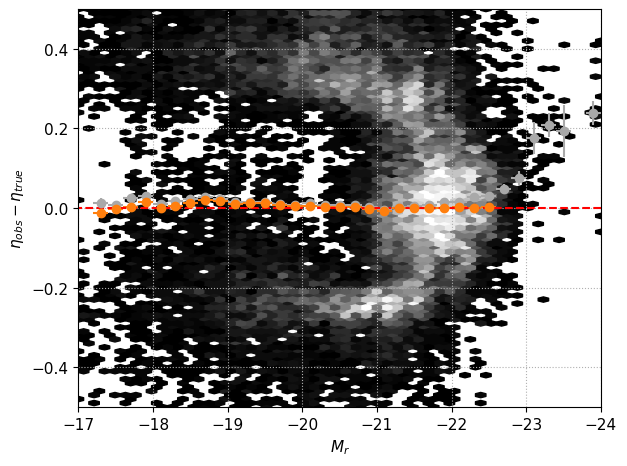

In [126]:
Mr_bins = np.arange(-24, -17, 0.2)
dMr = 0.5*np.diff(Mr_bins)
Mrc = 0.5*(Mr_bins[1:] + Mr_bins[:-1])

plt.figure(tight_layout=True)

plt.hexbin(mock['R_ABSMAG_SB26_MOCK'][~mock['MAIN']], 
           eta_mock[~mock['MAIN']] - eta_true[~mock['MAIN']], 
           cmap='Greys_r', 
           vmin=1, 
           vmax=50, 
           mincnt=1, 
           gridsize=(50, 50), 
           extent=(-24, -17, -0.5, 0.5))

# plt.hexbin(mock['R_ABSMAG_SB26_MOCK'][mock_main], 
#            eta_mock[mock_main] - eta_true[mock_main], 
#            cmap='viridis', 
#            vmin=1, 
#            vmax=400, 
#            mincnt=1, 
#            gridsize=(50, 50), 
#            extent=(-24, -17, -0.5, 0.5))

_, dn_avg, dn_std = profile_histogram(mock['R_ABSMAG_SB26_MOCK'], 
                                      eta_mock - eta_true, 
                                      Mr_bins, median=True)
plt.errorbar(Mrc, dn_avg, xerr=dMr, yerr=dn_std, fmt='o', color='darkgrey')

_, dn_avg, dn_std = profile_histogram(mock['R_ABSMAG_SB26_MOCK'][mock['MAIN']], 
                                      eta_mock[mock['MAIN']] - eta_true[mock['MAIN']], 
                                      Mr_bins, 
                                      median=True)
plt.errorbar(Mrc, dn_avg, xerr=dMr, yerr=dn_std, fmt='o', color='tab:orange')

plt.hlines(0, -24, -17, linestyles='dashed', colors='r')

plt.grid(ls=':')

plt.xlim((-17,-24))
plt.ylim(-0.5, 0.5)

plt.xlabel('$M_r$')
plt.ylabel('$\eta_{obs} - \eta_{true}$');

## Correlation with redshift

/tmp/ipykernel_1377377/3818747994.py:50: RuntimeWarning: invalid value encountered in true_divide
  e = np.sqrt((mean2 - mean**2) / (N - 1))


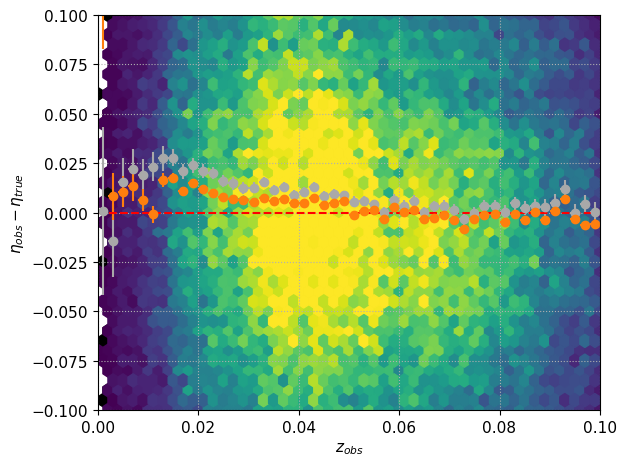

In [128]:
_zbins = np.arange(0, 0.2, 0.002)
dz = 0.5*np.diff(_zbins)
zc = 0.5*(_zbins[1:] + _zbins[:-1])

plt.figure(tight_layout=True)

plt.hexbin(mock['zobs'][~mock['MAIN']], 
           eta_mock[~mock['MAIN']] - eta_true[~mock['MAIN']], 
           cmap='Greys_r', 
           vmin=1, 
           vmax=50, 
           mincnt=1, 
           gridsize=(50, 100), 
           extent=(0, 0.1, -0.5, 0.5))

plt.hexbin(mock['zobs'][mock['MAIN']], 
           eta_mock[mock['MAIN']] - eta_true[mock['MAIN']], 
           cmap='viridis', 
           vmin=1, 
           vmax=100, 
           mincnt=1, 
           gridsize=(50, 100), 
           extent=(0, 0.1, -0.5, 0.5))

_, dn_avg, dn_std = profile_histogram(mock['zobs'], 
                                      eta_mock - eta_true, 
                                      _zbins, median=True)
plt.errorbar(zc, dn_avg, xerr=dz, yerr=dn_std, fmt='o', color='darkgrey')

_, dn_avg, dn_std = profile_histogram(mock['zobs'][mock['MAIN']], 
                                      eta_mock[mock['MAIN']] - eta_true[mock['MAIN']], 
                                      _zbins, 
                                      median=True)
plt.errorbar(zc, dn_avg, xerr=dz, yerr=dn_std, fmt='o', color='tab:orange')

plt.hlines(0, 0, 0.1, linestyles='dashed', colors='r')

plt.grid(ls=':')

plt.xlim(0, 0.1)
plt.ylim(-0.1, 0.1)

plt.xlabel('$z_{obs}$')
plt.ylabel('$\eta_{obs} - \eta_{true}$');

In [175]:
# fig, ax = plt.subplots(1,1, figsize=(6,4), tight_layout=True)
# ax.hist((eta_mock - eta_true) / eta_err_mock, bins=np.arange(-10,10.2,0.2))
# ax.set(xlabel=r'$(\eta_\mathrm{mock} - \eta_\mathrm{true})/\sigma_\eta$',
#        yscale='log')

## Write Output to FITS

In [130]:
{ 'a' : a_mcmc} | \
{ f'b{k+1}' : b_mcmc[k] for k in range(len(b_mcmc)) } | \
{ 'sigma' : sigma_mcmc } | \
{ 'ellipse_std' : ellipse_sigma }

{'a': -7.191515964891369,
 'b1': 12.858960480920288,
 'b2': 13.563494978804027,
 'b3': 14.083281525506461,
 'b4': 14.504485946426394,
 'b5': 14.873042769581382,
 'b6': 15.17760826924961,
 'b7': 15.465226533116908,
 'b8': 15.69169500278628,
 'b9': 15.903301480988839,
 'b10': 16.104170307533046,
 'b11': 16.29505550628478,
 'b12': 16.467440116679093,
 'b13': 16.611206827442086,
 'b14': 16.775393073422027,
 'b15': 16.90035896544905,
 'b16': 17.03378643743364,
 'b17': 17.180165573395648,
 'b18': 17.27924478781527,
 'sigma': 0.4119757378883902,
 'ellipse_std': 2.5}

In [177]:
outfile = os.path.join('/global/cfs/cdirs/desi/science/td/pv/mocks/TF_mocks/fullmocks/v0.5.4',
                       os.path.basename(mockfile).replace('.dat.hdf5', '.fits').replace('BGS_PV', 'TF'))

# hdr = fits.Header(dict(NTF=len(mock),
#                        a=a_mcmc,
#                        b=b_mcmc,
#                        sigma=sigma_mcmc,
#                        cov_aa=cov_mcmc[0][0],
#                        cov_ab=cov_mcmc[0][1],
#                        cov_as=cov_mcmc[0][2],
#                        cov_bb=cov_mcmc[1][1],
#                        cov_bs=cov_mcmc[1][2],
#                        cov_ss=cov_mcmc[2][2]))

hdr = fits.Header({ 'NTF' : len(mock) } | \
                  { 'a' : a_mcmc } | \
                  { f'b{k+1}' : b_mcmc[k] for k in range(len(b_mcmc)) } | \
                  { 'sigma' : sigma_mcmc} | \ 
                  { 'ellipse_std' : ellipse_sigma })      

col01 = fits.Column(name='RA',            format='D', array=mock['ra'].to_numpy())
col02 = fits.Column(name='DEC',           format='D', array=mock['dec'].to_numpy())
col03 = fits.Column(name='ZOBS',          format='D', array=mock['zobs'].to_numpy())
col04 = fits.Column(name='ZCOS',          format='D', array=mock['zcos'].to_numpy())
col05 = fits.Column(name='vx',            format='D', array=mock['vx'].to_numpy())
col06 = fits.Column(name='vy',            format='D', array=mock['vy'].to_numpy())
col07 = fits.Column(name='vz',            format='D', array=mock['vz'].to_numpy())
col08 = fits.Column(name='DWARF',         format='L', array=mock['DWARF'].to_numpy())
col09 = fits.Column(name='MAIN',          format='L', array=mock['MAIN'].to_numpy())
col10 = fits.Column(name='LOGVROT',       format='D', array=mock['LOGVROT_MOCK'].to_numpy())
col11 = fits.Column(name='R_ABSMAG_SB26', format='D', array=mock['R_ABSMAG_SB26_MOCK'].to_numpy())
col12 = fits.Column(name='LOGDIST_TRUE',  format='D', array=eta_true)
col13 = fits.Column(name='LOGDIST',       format='D', array=eta_mock.to_numpy())
col14 = fits.Column(name='LOGDIST_ERR',   format='D', array=eta_err_mock.to_numpy())
col15 = fits.Column(name='Y1_COMP',       format='D', array=mock['Y1_COMP'].to_numpy())
col16 = fits.Column(name='Y3_COMP',       format='D', array=mock['Y3_COMP'].to_numpy())

hdulist = fits.BinTableHDU.from_columns([col01, col02, col03, col04, col05,
                                         col06, col07, col08, col09, col10,
                                         col11, col12, col13, col14, col15,
                                         col16],
                                        header=hdr)
hdulist.writeto(outfile, overwrite=True)

shutil.chown(outfile, group='desi')

In [84]:
# !jupyter nbconvert --to script TFR_mock_gen_v0.ipynb